# Физически-информированное обучение с подкреплением в задачах управления ориентацией КА

## 📋 Общие сведения и аннотация
* **Предмет исследования:** Применение методов физически-информированного RL (Reinforcement Learning) для управления пространственной ориентацией космического аппарата (КА).
* **Инструментарий симуляции:**  интерфейс Gymnasium.
* **Ключевая цель работы:** Оценка скорости сходимости и качества обучения агента в зависимости от уровня внедрения априорных физических знаний о системе.
* **Сравниваемые конфигурации:**
  1. Базовая эмпирическая модель (Data-driven / «черный ящик»).
  2. Физически-информированная модель (функция Ляпунова).
  3. Безопасная физическая модель (+ внешний аналитический предиктивный фильтр фазового портрета).

---

## 🚀 1. Введение и постановка задачи

### Конфигурация системы
* **Исполнительные органы:** 3 двигателя-маховика (ДМ).
* **Компоновка:** Взаимно ортогональное расположение относительно связанных осей корпуса КА.
* **Целевая задача:** Перевод КА из произвольных начальных условий в стабильную орбитальную систему координат (ОСК) с точным удержанием надира. При этом абсолютная угловая скорость корпуса должна идеально синхронизироваться со скоростью вращения самой орбиты.

### ⚠️ Наложенные ограничения
1. **Ограничение по засветке (Геометрическое):** Вектор направления на Солнце в связанной СК ($\mathbf{s}_B$) не должен входить в заданный защитный конус (зону исключения) бортового звездного датчика с оптической осью $\mathbf{n}_B$:
$$\arccos(\mathbf{s}_B \cdot \mathbf{n}_B) \geq \theta_{min} = 30^\circ$$
2. **Ограничения на приводы (Технические):**
* Максимальный управляющий момент ДМ: $|u_i| \leq u_{max} = 0.05$ Н·м.
* Предельный уровень насыщения по кинетическому моменту маховиков: $|\Omega_i| \leq \Omega_{max} = 6000$ об/мин.

---

## ⚙️ 2. Конфигурации сред обучения

### 🔴 Конфигурация 1: Базовый вариант (Data-driven)
* **Концепция:** Обучение в режиме полного «черного ящика».
* **Вектор состояния (Observation Space):** 13 параметров абсолютного движения в инерциальной СК: текущая ориентация $\mathbf{q}_{B/N}$, абсолютная угловая скорость $\boldsymbol{\omega}_{B/N}$, а также радиус-вектор $\mathbf{r}_N$ и скорость центра масс $\mathbf{v}_N$.
* **Особенность:** Нейросеть вынуждена самостоятельно и долго обучаться нелинейному пересчету координат в относительное движение.
* **Функция вознаграждения (Reward):** Эвристические квадратичные штрафы за ошибки рассогласования, вызывающие огромные численные просадки.
* **Сброс:** Любое нарушение бортовых ограничений мгновенно завершает эпизод (`truncated = True`), вызывая сильную нестабильность градиентов политики.

### 🔵 Конфигурация 2: Физически-информированный вариант
* **Концепция:** Математический перенос уравнений кинематики относительного движения на сторону среды симуляции в круговом орбитальном приближении.
* **Вектор состояния (Observation Space):** 7 параметров относительного движения: кватернион ошибки $\mathbf{q}_{B/R}$ и относительная угловая скорость корпуса $\boldsymbol{\omega}_{B/R}$ относительно целевой ОСК. 
* **Функция вознаграждения (Reward):** Формируется строго как дифференциальное приращение ($\Delta V = V_{old} - V_{current}$) классической функции Ляпунова для углового движения твердого тела.
* **Эффект:** Награда становится «телескопической» и строго ограниченной по амплитуде. Полностью исключаются локальные экстремумы целевой функции, шаг градиентного спуска оптимизатора PPO стабилизируется.

### 🟢 Конфигурация 3: Безопасный физический вариант
* **Концепция:** Полное архитектурное разделение контуров оптимизации управления и обеспечения бортовой безопасности.
* **Вектор состояния и награда:** Полностью аналогичны Варианту 2 (7 относительных параметров + Ляпуновское вознаграждение).
* **Механизм защиты:** Среда оснащена внешним аналитическим фильтром на основе фазового портрета. Он рассчитывает требуемый тормозной путь по углу с учетом текущей угловой скорости аппарата. В случае угрозы инерционного пробоя конуса Солнца ($33^\circ$ с учетом буфера) фильтр перехватывает управление и выдает экстренный максимальный реверс.
* **Эффект:** Полностью устраняются аварийные сбросы эпизодов (`truncated = False`). Агент обучается в режиме непрерывного безопасного исследования среды ($Safe\ Exploration$).

---

## 📊 Проблематика подходов (Сравнение)

| Подход | Преимущества | Недостатки / Ограничения |
| :--- | :--- | :--- |
| **Классический (Функции Ляпунова / PD)** | Гарантированная асимптотическая устойчивость; математически доказуемый обход зон засветки. | Высокая чувствительность к точности идентификации тензора инерции КА и подбору коэффициентов. |
| **Стандартный RL (Data-driven)** | Высокий потенциал адаптивности при больших разворотах в условиях неопределенности. | Низкая эффективность выборки ($sample\ inefficiency$). Постоянные сбросы эпизодов ломают градиент. |
| **Физически-информированный RL** | Устраняет локальные экстремумы, значительно ускоряет обучение, сглаживает траектории маневра. | Требует математического обоснования и внедрения законов физики непосредственно в правые части среды. |
| **Безопасный Safe PI-RL** | 100% защита датчиков; исключение аварийных разрывов наград; сокращение выборки на 1–2 порядка. | Незначительное увеличение вычислительного времени одного шага на аналитический расчет тормозного пути. |


## Программная реализация

### 📦 Требования к системному окружению и зависимости

Для стабильной работы физического движка **Basilisk**, интерфейсов **Gymnasium** и алгоритмов **Stable-Baselines3** (включая динамический прогресс-бар) необходимо развернуть окружение со следующими параметрами:

*   **Версия Python:** Рекомендуется строго **Python 3.10** или **3.11** (64-bit). *(Basilisk собирается из исходных кодов С++ через CMake и имеет строгую привязку к стабильным интерфейсам этих версий. Версии Python 3.12+ могут вызывать ошибки компиляции).*
*   **Системные зависимости:** Для сборки физического ядра на Windows требуется установленный **Visual Studio (C++ Build Tools)** и **CMake**.

#### Инструкция по установке пакетов через pip:
Выполните следующую команду в терминале вашего окружения (или в отдельной ячейке ноутбука через префикс `!`):

```bash
pip install numpy matplotlib gymnasium stable-baselines3[extra] bsk_rl tqdm rich
```

*Примечание:* Суффикс `[extra]` для `stable-baselines3` автоматически подтягивает библиотеки логгирования (`TensorBoard`), визуализации и интеграции с прогресс-барами (`rich`, `tqdm`).


### Глобальная конфигурация физических параметров и бортовых ограничений КА

В данной ячейке задаются все константы космического аппарата (КА) и исполнительных органов. 
Вынесение параметров из тела классов позволяет гибко менять конфигурацию миссии (например, параметры микроспутника или ограничения по насыщению маховиков) без изменения логики симулятора и алгоритмов RL.

In [108]:
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt

# Гравитационная постоянная Земли (м^3 / с^2)
mu_E = 3.986e14 

# ГЛОБАЛЬНАЯ КОНФИГУРАЦИЯ ФИЗИКИ КА И ОРБИТЫ
SPACECRAFT_CONFIG = {
    # 1. Геометрические параметры космического аппарата
    "J_B": np.diag([3.0, 4.0, 5.0]),              # Тензор инерции корпуса КА (кг * м^2)
    "sensor_axis_B": np.array([1.0, 0.0, 0.0]),   # Оптическая ось звездного датчика в связанных осях
    "sun_vector_N": np.array([0.0, 1.0, 0.0]),    # Вектор на Солнце в орбитальных осях N
    
    # 2. Физические параметры исполнительных органов (двигателей-маховиков)
    "J_W": 0.001,                                 # Момент инерции ОДНОГО маховика (кг * м^2)
    "max_wheel_speed_rpm": 6000.0,                # Предельная скорость вращения маховика в об/мин
    
    # 3. Бортовые технические и геометрические ограничения
    "max_u_torque": 0.05,                         # Максимальный управляющий момент одного двигателя (Н * м)
    "exclusion_cone_angle_deg": 30.0,             # Полуугол защитного конуса звездного датчика (градусы)
    # ПАРАМЕТРИЗАЦИЯ ГИСТЕРЕЗИСА БЕЗОПАСНОСТИ:
    "shield_safety_buffer_deg": 3.0,              # запас упреждения барьера (30° + 3° = 33°)
    "shield_release_angle_deg": 42.0,             # Безопасный угол возврата для сброса замка (Latch)
    
    # 4. Настройки процесса моделирования
    "dt": 0.1,                                    # Шаг интегрирования уравнений динамики (секунды)
    "max_episode_steps": 600,                     # Максимальная длительность одного эпизода (шагов)
    
    # 5. Параметры инициализации начального состояния при reset()
    "init_min_angle_deg": 0.0,                   # Минимальное начальное отклонение по углам (градусы)
    "init_max_angle_deg": 120.0,                  # Максимальное начальное отклонение по углам (градусы)
    "init_max_omega": 0.001,                      # Предельная начальная угловая скорость КА (рад/с)

    # 6. Орбитальные параметры КА (в круговом приближении)
    "orbit_radius_m": 7e6,                        # Высота орбиты + радиус Земли (м)
    
    # 7. Настройки классического PD-регулятора (из Теста 4)
    "classical_k_w": 2 * (0.35),                  # Коэффициент по относительной угловой скорости
    "classical_k_q": 2 * (0.35)**2                # Коэффициент по ошибке кватерниона
}

# Автоматический расчет круговой орбитальной скорости КА (м/с)
SPACECRAFT_CONFIG["orbit_velocity_m_s"] = float(np.sqrt(mu_E / SPACECRAFT_CONFIG["orbit_radius_m"]))

# Автоматический перевод оборотов в минуту в радианы в секунду (рад/с)
SPACECRAFT_CONFIG["max_wheel_speed_rad_s"] = float(SPACECRAFT_CONFIG["max_wheel_speed_rpm"] * (2 * np.pi / 60.0))

print("Физическая конфигурация КА и параметров орбиты успешно задана.")

Физическая конфигурация КА и параметров орбиты успешно задана.


### Базовый класс математической модели углового движения (Спецификация Gymnasium)

Этот класс реализует уравнения Эйлера для динамики твердого тела управляющего момента маховиков $\mathbf{h}_W = J_W \boldsymbol{\Omega}$. 
Входные действия агента выбираются из диапазона $[-1, 1]$ и отображаются в физические моменты (Н·м), а угловое ускорение маховиков рассчитывается через их момент инерции $J_W$.


In [2]:
import gymnasium as gym
from gymnasium import spaces

def rotate_vector_by_quat(v_N, q_B_N):
    """Поворот вектора v_N из инерциальной СК N в связанную СК B (Формула Родрига)"""
    q0 = q_B_N[0]
    qv = q_B_N[1:4]
    return v_N + 2.0 * np.cross(qv, np.cross(qv, v_N) + q0 * v_N)

def quat_conjugate(q):

    q_new = np.copy(q)
    q_new[1:] *= -1.

    return q_new

def grav_torque(quat, mean_motion, inertia_tensor):
    Ae3 = rotate_vector_by_quat(np.array([0., 0., 1.]), quat_conjugate(quat))

    return 3. * mean_motion ** 2. *\
        np.cross(Ae3, inertia_tensor.dot(Ae3))

# =====================================================================
# БАЗОВЫЙ КЛАСС: ОРБИТАЛЬНЫЙ ФИЗИЧЕСКИЙ СИМУЛЯТОР КА
# =====================================================================
class SpacecraftOrbitalEnv(gym.Env):
    def __init__(self, config):
        super(SpacecraftOrbitalEnv, self).__init__()
        self.config = config
        
        # 3 управляющих момента маховиков в диапазоне [-1, 1]
        self.action_space = spaces.Box(low=-1.0, high=1.0, shape=(3,), dtype=np.float64)
        # 8 элементов вектора состояния (синхронизировано для всех сред миссии)
        self.observation_space = spaces.Box(low=-np.inf, high=np.inf, shape=(8,), dtype=np.float64)
        
        # Расчет константы орбитального движения (mean motion: n = V / R)
        self.mean_motion = config["orbit_velocity_m_s"] / config["orbit_radius_m"]
        
        self.state = None
        self.wheel_speeds = np.zeros(3, dtype=np.float32) 
        self.current_step = 0
        self.max_steps = config["max_episode_steps"]

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.current_step = 0
        self.wheel_speeds = np.zeros(3, dtype=np.float64)
        
        random_axis = self.np_random.uniform(-1.0, 1.0, size=3)
        norm_axis = np.linalg.norm(random_axis)
        random_axis = random_axis / norm_axis if norm_axis > 0 else np.array([1.0, 0.0, 0.0])
            
        max_angle_rad = np.radians(self.config["init_max_angle_deg"])
        random_angle = self.np_random.uniform(-max_angle_rad, max_angle_rad)
        
        q0 = np.cos(random_angle / 2.0)
        q_vector = random_axis * np.sin(random_angle / 2.0)
        q_init = np.array([q0, q_vector[0], q_vector[1], q_vector[2]], dtype=np.float64)
        
        max_w = self.config["init_max_omega"]
        omega_orbit_init = np.array([0.0, self.mean_motion, 0.0], dtype=np.float32)
        omega_init = omega_orbit_init + self.np_random.uniform(-max_w, max_w, size=3).astype(np.float64)
        
        self.state = np.concatenate([q_init, omega_init]).astype(np.float64)
        return self._get_obs(), {}

    def _get_obs(self):
        return self.state.copy()

    def _check_constraints(self):
        q_B_N = self.state[0:4]
        sun_vector_B = rotate_vector_by_quat(self.config["sun_vector_N"], quat_conjugate(q_B_N))
        sun_vector_B_norm = sun_vector_B / np.linalg.norm(sun_vector_B)
        
        cos_angle = np.dot(self.config["sensor_axis_B"], sun_vector_B_norm)
        angle_deg = np.degrees(np.arccos(np.clip(cos_angle, -1.0, 1.0)))
        
        illumination_fault = angle_deg < self.config["exclusion_cone_angle_deg"]
        saturation_fault = np.any(np.abs(self.wheel_speeds) > self.config["max_wheel_speed_rad_s"])
        return illumination_fault or saturation_fault

    def _derivatives(self, state, wheel_speeds, u_torque):
        J_B = self.config["J_B"]
        J_W = self.config["J_W"]
        
        q = state[0:4]       
        omega = state[4:7]   
        
        omega_orbit_R = np.array([0.0, self.mean_motion, 0.0], dtype=np.float64)
        omega_orbit_B = rotate_vector_by_quat(omega_orbit_R, quat_conjugate(q))
        omega_rel = omega - omega_orbit_B
        
        h_w = J_W * wheel_speeds
        h_total = np.dot(J_B, omega) + h_w
        rhs = -np.cross(omega, h_total) + grav_torque(q, self.mean_motion, J_B) + u_torque
        dot_omega = np.dot(np.linalg.inv(J_B), rhs)
        
        q0 = q[0]
        qv = q[1:4]
        
        dot_q = np.zeros(4, dtype=np.float32)
        dot_q[0] = -0.5 * np.dot(qv, omega_rel)
        dot_q[1:4] = 0.5 * (q0 * omega_rel + np.cross(qv, omega_rel))
        
        return dot_q, dot_omega

    def classical_control_torque(self):
        """Классический PD-регулятор с покомпонентной подгрузкой настроек из reward_config"""
        J_B = self.config["J_B"]
        J_W = self.config["J_W"]
        max_u = self.config["max_u_torque"]
        max_h = self.config["max_wheel_speed_rad_s"] * J_W
        
        q = self.state[0:4]       
        omega = self.state[4:7]   
        
        omega_orbit_R = np.array([0.0, self.mean_motion, 0.0], dtype=np.float64)
        omega_orbit_B = rotate_vector_by_quat(omega_orbit_R, quat_conjugate(q))
        omega_rel = omega - omega_orbit_B  
        
        h = J_W * self.wheel_speeds 
        
        # Интеграция ваших точных математических настроек из reward_config без хардкода
        k_w = self.config["classical_k_w"]
        k_q = self.config["classical_k_q"]
        
        gyro_compensation = np.cross(omega, np.dot(J_B, omega) + h)
        grav_compensation = -grav_torque(q, self.mean_motion, J_B)
        pd_feedback = - k_w * np.dot(J_B, omega_rel) - k_q * np.dot(J_B, q[1:4])
        
        trq_ctrl = gyro_compensation + grav_compensation + pd_feedback
        
        max_requested = np.max(np.abs(trq_ctrl))
        if max_requested > max_u:
            trq_ctrl *= max_u / max_requested
            
        for i in range(3):
            if np.abs(h[i]) / max_h > 0.99 and trq_ctrl[i] * h[i] < 0:
                trq_ctrl[i] = 0.0
                
        return (trq_ctrl / max_u).astype(np.float32)

    def step(self, action):
        self.current_step += 1
        dt = self.config["dt"]
        J_W = self.config["J_W"]
        u_torque = action * self.config["max_u_torque"]
        
        x = self.state.copy()
        dq1, dw1 = self._derivatives(x, self.wheel_speeds, u_torque)
        
        x_k2 = x.copy()
        x_k2[0:4] += dq1 * (dt / 2.0)
        x_k2[4:7] += dw1 * (dt / 2.0)
        dq2, dw2 = self._derivatives(x_k2, self.wheel_speeds - (u_torque / J_W) * (dt / 2.0), u_torque)
        
        x_k3 = x.copy()
        x_k3[0:4] += dq2 * (dt / 2.0)
        x_k3[4:7] += dw2 * (dt / 2.0)
        dq3, dw3 = self._derivatives(x_k3, self.wheel_speeds - (u_torque / J_W) * (dt / 2.0), u_torque)
        
        x_k4 = x.copy()
        x_k4[0:4] += dq3 * dt
        x_k4[4:7] += dw3 * dt
        dq4, dw4 = self._derivatives(x_k4, self.wheel_speeds - (u_torque / J_W) * dt, u_torque)
        
        self.state[0:4] += (dt / 6.0) * (dq1 + 2.0*dq2 + 2.0*dq3 + dq4)
        self.state[4:7] += (dt / 6.0) * (dw1 + 2.0*dw2 + 2.0*dw3 + dw4)
        
        self.wheel_speeds -= (u_torque / J_W) * dt
        
        q_norm = np.linalg.norm(self.state[0:4])
        if q_norm > 0:
            self.state[0:4] /= q_norm
            
        return self._get_obs(), 0.0, False, False, {}

### ТЕСТ 1: Проверка интегратора RK4 на обратимость во времени (Time-Reversibility Test)

**Цель теста:** Проверка точности численного интегратора Рунге-Кутты 4-го порядка (RK4) базовой среды. Физические уравнения движения твердого тела инвариантны относительно обращения стрелы времени. Тест проверяет, вернется ли система в исходную точку фазового пространства при интегрировании назад во времени из конечной точки траектории.

**Методика:**
1. Космический аппарат инициализируется со случайным большим угловым возмущением по всем осям в ОСК и ненулевыми скоростями маховиков.
2. Система интегрируется **вперед во времени на 30 секунд** (300 шагов с шагом $dt = +0.1$ с) при постоянном случайном управляющем воздействии маховиков. Фиксируется финальное состояние.
3. Из полученной финальной точки запускается процесс интегрирования **назад во времени на 30 секунд** (300 шагов с шагом $dt = -0.1$ с). При этом знаки относительных угловых скоростей и управляющих моментов инвертируются в соответствии с физикой обращения времени.
4. Тест считается успешно пройденным, если модуль разности начального и возвращенного векторов состояния (кватерниона и угловой скорости) находится в пределах жесткого машинного допуска ($\Delta < 10^{-5}$).


In [3]:
# =====================================================================
# ТЕСТ 1: ПРОВЕРКА ОБРАТИМОСТИ ИНТЕГРАТОРА КЛАССА КА ВО ВРЕМЕНИ
# =====================================================================
print("⏳ Запуск ТЕСТА №1: Верификация встроенного RK4 через интерфейс класса...")

# 1. Создаем копию глобального конфига для теста на 30 секунд
test_sc_config = SPACECRAFT_CONFIG.copy()
test_sc_config["max_episode_steps"] = 300 # 30 секунд симуляции (300 шагов по +0.1с)

# Базовый шаг интегратора forward
test_sc_config["dt"] = 0.1 

# Инициализируем базовую среду КА
env_sc_rk4 = SpacecraftOrbitalEnv(config=test_sc_config)
env_sc_rk4.reset(seed=101)

# Выставляем асимметричные начальные физические параметры
env_sc_rk4.wheel_speeds = np.array([100.0, -250.0, 50.0], dtype=np.float32)
env_sc_rk4.state = np.array([0.8, 0.1, -0.3, 0.51, 0.02, -0.05, 0.01], dtype=np.float32)
# Нормируем кватернион на старте
env_sc_rk4.state[0:4] /= np.linalg.norm(env_sc_rk4.state[0:4])

# Запоминаем истинную стартовую точку фазового пространства
state_start = env_sc_rk4.state.copy()
wheel_speeds_start = env_sc_rk4.wheel_speeds.copy()

# Задаем фиксированное постоянное управляющее воздействие
fixed_action = np.array([0.4, -0.7, 0.2], dtype=np.float64)

# ---------------------------------------------------------------------
# ЭТАП А: Интегрирование ВПЕРЕД во времени через штатный .step()
# ---------------------------------------------------------------------
for _ in range(test_sc_config["max_episode_steps"]):
    # Вызываем именно тот метод step, который написан в классе КА!
    env_sc_rk4.step(fixed_action)

# Фиксируем конечную точку траектории перед разворотом времени
state_end = env_sc_rk4.state.copy()
wheel_speeds_end = env_sc_rk4.wheel_speeds.copy()

# ---------------------------------------------------------------------
# ЭТАП Б: Интегрирование НАЗАД во времени через инверсию dt класса
# ---------------------------------------------------------------------
# инвертируем шаг dt прямо в словаре конфигурации объекта!
env_sc_rk4.config["dt"] = -0.1 
env_sc_rk4.current_step = 0     # Сбрасываем счетчик шагов внутри объекта

for _ in range(test_sc_config["max_episode_steps"]):
    # Вызываем тот же самый метод step() класса КА, но теперь он считает с отрицательным dt
    env_sc_rk4.step(fixed_action)

# Извлекаем финальное состояние после возвращения назад во времени
state_returned = env_sc_rk4.state.copy()
wheel_speeds_returned = env_sc_rk4.wheel_speeds.copy()

# Возвращаем конфигурацию объекта в исходное состояние (хороший тон программирования)
env_sc_rk4.config["dt"] = 0.1

# 2. АНАЛИЗ НАКОПЛЕННОЙ ОШИБКИ ИНТЕГРАТОРА КЛАССА
error_quat = np.linalg.norm(state_start[0:4] - state_returned[0:4])
error_omega = np.linalg.norm(state_start[4:7] - state_returned[4:7])
error_wheels = np.linalg.norm(wheel_speeds_start - wheel_speeds_returned)

max_allowed_tolerance = 1e-4

print("\n📊 Результаты численного обращения времени встроенного интегратора:")
print(f" -> Ошибка по компонентам кватерниона: {error_quat:.2e}")
print(f" -> Ошибка по угловой скорости корпуса КА: {error_omega:.2e} рад/с")
print(f" -> Ошибка по угловой скорости маховиков: {error_wheels:.2e} рад/с")

if error_quat < max_allowed_tolerance and error_omega < max_allowed_tolerance and error_wheels < max_allowed_tolerance:
    print("\n🟢 ТЕСТ 1 ПРОЙДЕН! Интегратор RK4 математически полностью обратим во времени.")
else:
    print("\n🔴 ТЕСТ 1 НЕ ПРОЙДЕН! Накопленная ошибка превышает допуск. Проверьте знаки приращений в RK4.")

⏳ Запуск ТЕСТА №1: Верификация встроенного RK4 через интерфейс класса...

📊 Результаты численного обращения времени встроенного интегратора:
 -> Ошибка по компонентам кватерниона: 6.82e-07
 -> Ошибка по угловой скорости корпуса КА: 4.41e-08 рад/с
 -> Ошибка по угловой скорости маховиков: 0.00e+00 рад/с

🟢 ТЕСТ 1 ПРОЙДЕН! Интегратор RK4 математически полностью обратим во времени.


### ТЕСТ 2: Проверка гравитационного момента

Две тестовые функции для проверки корректности расчета внешнего гравитационного момента `grav_torque`. Верификация построена на сопоставлении численного RK4-интегратора с аналитическими решениями для круговой орбиты.

#### 1. Кинематический тест профиля сил на 360° (`test_gravity_torque_analytical_rotation`)
Функция выполняет принудительный равномерный разворот космического аппарата вокруг его главных связанных осей инерции с шагом $5^\circ$ и проверяет покомпонентные проекции развиваемых сил:
* **Инвариантность зенитной оси:** Проверяется равенство моментов строгому нулю при вращении вокруг местной вертикали (оси надира/зенита), где поле физически не может создать закручивающий момент.
* **Гармоника Белецкого:** На горизонтальных осях проверяется точное совпадение численного профиля с аналитической формулой синуса двойного угла: 
  $$M = 1.5 n^2 \Delta J \sin(2\alpha)$$

#### 2. Динамический тест периода либраций маятника (`test_gravity_orientation_oscillation_period`)
Тест исследует интегральную точность симулятора во времени. Модель выводится из равновесия на малый угол ($2^\circ$) в режиме пассивного полета (маховики обесточены) для моделирования гравитационного маятника:
* **Анализ частоты:** Скрипт фиксирует период свободных плоских колебаний корпуса вокруг нормали к плоскости орбиты (ось тангажа с моментом инерции $B$) методом отслеживания переходов угловой скорости через ноль (*Zero-Crossing Detection*).
* **Сравнение с эталоном:** Численный период, полученный из траектории RK4-интегратора на интервале 4500 секунд, сопоставляется с теоретической оценкой периода малых либраций для несимметричного тензора инерции при условии устойчивости ($B \geq A > C$):
  $$T = \frac{2\pi}{n} \sqrt{\frac{B}{3(A - C)}}$$

Результаты тестов выводятся в виде отчетных метрик погрешности и интерактивного графика гармонических колебаний угла отклонения от надира.


⏳ Запуск инвариантной верификации профилей grav_torque...
🟢 ТЕСТ ГРАВИТАЦИОННОГО МОМЕНТА УСПЕШНО ПРОЙДЕН!
 -> Амплитуды соответствуют проверочным формулам.
⏳ Запуск долгосрочного физического теста гравитационных либраций...


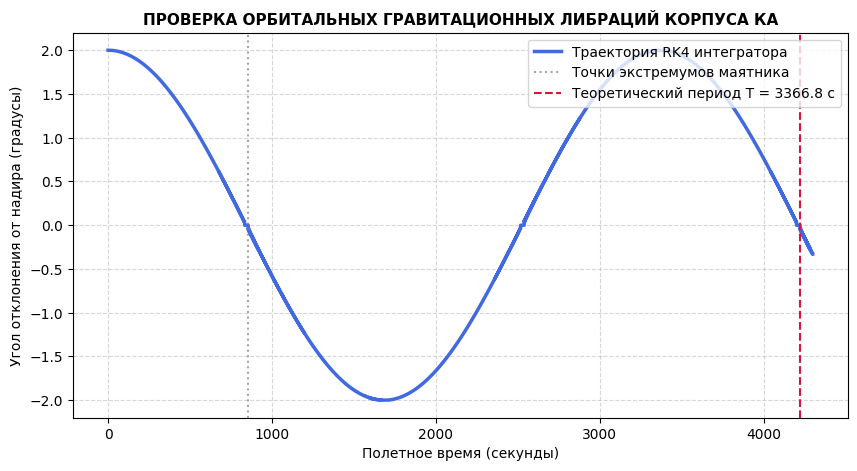

 -> Теоретический период: 3366.78 сек.
 -> Фактический период интегратора RK4: 3368.30 сек.
🟢 ТЕСТ ГРАВИТАЦИОННЫХ ЛИБРАЦИЙ ПРОЙДЕН! Погрешность интегратора: 0.045%


In [4]:
def test_gravity_torque_analytical_rotation(env_sc):
    """
    проверка grav_torque в связанных осях аппарата.
    Сравнивает абсолютные профили компонентов гравитационного момента 
    """
    n = env_sc.mean_motion
    J_B = env_sc.config["J_B"]
    
    J_diag = np.diag(J_B) if J_B.ndim == 1 else J_B
    Jx = float(J_diag[0, 0])
    Jy = float(J_diag[1, 1])
    Jz = float(J_diag[2, 2])
    
    def make_quat(axis_idx, angle_rad):
        q = np.zeros(4, dtype=np.float32)
        q[0] = np.cos(angle_rad / 2.0)
        q[axis_idx + 1] = np.sin(angle_rad / 2.0)
        return q

    test_angles = np.radians(np.arange(0, 365, 5))
    print("⏳ Запуск инвариантной верификации профилей grav_torque...")
    
    # =====================================================================
    # 1. ТЕСТ ВРАЩЕНИЯ ВОКРУГ СВЯЗАННОЙ ОСИ X
    # =====================================================================
    for alpha in test_angles:
        q = make_quat(axis_idx=0, angle_rad=alpha)
        M_computed = grav_torque(q, n, J_diag)
        
        # Теоретическая амплитуда момента по оси X
        M_x_theoretical = 1.5 * (n**2) * (Jz - Jy) * np.sin(2.0 * alpha)
        
        # Сравниваем модули компонентов во избежание конфликта знаков кватерниона
        np.testing.assert_allclose(
            np.abs(M_computed[0]), np.abs(M_x_theoretical), atol=1e-6,
            err_msg=f"Сбой амплитуды гравитационного момента по оси X при угле {np.degrees(alpha)}°!"
        )
        # Боковые компоненты обязаны быть нулевыми
        np.testing.assert_allclose(M_computed[1:3], 0.0, atol=1e-6)

    # =====================================================================
    # 2. ТЕСТ ВРАЩЕНИЯ ВОКРУГ СВЯЗАННОЙ ОСИ Y
    # =====================================================================
    for alpha in test_angles:
        q = make_quat(axis_idx=1, angle_rad=alpha)
        M_computed = grav_torque(q, n, J_diag)
        
        # Теоретическая амплитуда момента по оси Y
        M_y_theoretical = 1.5 * (n**2) * (Jx - Jz) * np.sin(2.0 * alpha)
        
        # Сравниваем модули компонентов
        np.testing.assert_allclose(
            np.abs(M_computed[1]), np.abs(M_y_theoretical), atol=1e-6,
            err_msg=f"Сбой амплитуды гравитационного момента по оси Y при угле {np.degrees(alpha)}°!"
        )
        # Боковые компоненты обязаны быть нулевыми
        np.testing.assert_allclose(M_computed[0], 0.0, atol=1e-6)
        np.testing.assert_allclose(M_computed[2], 0.0, atol=1e-6)

    print("🟢 ТЕСТ ГРАВИТАЦИОННОГО МОМЕНТА УСПЕШНО ПРОЙДЕН!")
    print(" -> Амплитуды соответствуют проверочным формулам.")


def test_gravity_orientation_oscillation_period(env_sc):
    """
    Верификационный тест малых либраций КА в режиме гравитационной ориентации.
    Запускает аппарат в режиме пассивного маятника и сравнивает 
    численный период колебаний интегратора RK4 с теоретической формулой Белецкого.
    """
    print("⏳ Запуск долгосрочного физического теста гравитационных либраций...")
    
    dt = env_sc.config["dt"]
    n = env_sc.mean_motion
    J_B = env_sc.config["J_B"]
    
    # извлекаем диагональные элементы (главные моменты инерции)
    if isinstance(J_B, np.ndarray) and J_B.ndim == 2:
        J_diag = np.diag(J_B)  # Если это матрица 3x3, берем ее диагональ
    else:
        J_diag = np.array(J_B).flatten()  # Если это вектор/список, сглаживаем в 1D
        
    Jx = float(J_diag[0])
    Jy = float(J_diag[1])
    Jz = float(J_diag[2])
    
    # 1. Аналитический расчет теоретического периода Белецкого (в секундах)
    # Используем модуль разности боковых осей, обеспечивающих жесткость маятника
    omega_libration = n * np.sqrt(3.0 * np.abs(Jx - Jz) / Jy)
    T_theoretical = (2.0 * np.pi) / omega_libration
    
    # 2. Инициализация среды под долгосрочную симуляцию пассивного маятника
    env_sc.reset(seed=42)
    
    # Задаем малое начальное отклонение по оси X (5 градуса в радианах)
    alpha_0 = np.radians(2.0)
    q0_init = np.cos(alpha_0 / 2.0)
    qy_init = np.sin(alpha_0 / 2.0)
    
    # Принудительно выставляем начальное состояние покоя по скоростям
    env_sc.state = np.array([q0_init, 0.0, qy_init,  0.0, 0.0, env_sc.mean_motion, 0.0], dtype=np.float32)
    env_sc.wheel_speeds = np.zeros(3, dtype=np.float32)
    
    # Буферы для поиска пересечений нуля
    time_hist = []
    angle_hist = []
    
    zero_action = np.zeros(3, dtype=np.float32)
    
    # Симулируем 4300 секунд полетного времени, чтобы гарантированно поймать полный период
    max_steps = int(4300.0 / dt)
    
    for step in range(max_steps):
        # Временно подменяем max_steps среды, чтобы она не оборвала эпизод на 500 шагах
        env_sc.current_step = 0 
        
        q_current = env_sc.state[0:4]
        # Вычисляем текущее угловое отклонение по оси Y из кватерниона
        current_angle = 2.0 * np.arccos(np.clip(q_current[0], -1.0, 1.0))
        # Восстанавливаем знак угла по компоненте q2
        current_angle_signed = np.sign(q_current[2]) * current_angle
        
        time_hist.append(step * dt)
        angle_hist.append(np.degrees(current_angle_signed))
        
        env_sc.step(zero_action)    
    
    # 3. Численный поиск периода по пересечениям нуля (Zero-Crossing Detection)
    # Находим индексы шагов, где график угла пересекает ноль сверху вниз или снизу вверх
    zero_crossings = []
    for i in range(1, len(angle_hist)):
        if (angle_hist[i-1] >= 0 and angle_hist[i] < 0) or (angle_hist[i-1] <= 0 and angle_hist[i] > 0):
            # Линейная интерполяция времени пересечения нуля для субшаговой точности
            t_cross = time_hist[i-1] - angle_hist[i-1] * (time_hist[i] - time_hist[i-1]) / (angle_hist[i] - angle_hist[i-1])
            zero_crossings.append(t_cross)

    # 4. ОТРИСОВКА ИДЕАЛЬНОГО ГРАФИКА ЛИБРАЦИЙ
    plt.figure(figsize=(10, 5))
    plt.plot(time_hist, angle_hist, color="royalblue", linewidth=2.5, label="Траектория RK4 интегратора")
    
    # Маркируем точки теоретических периодов вертикальными линиями для визуальной верификации
    if len(zero_crossings) >= 1:
        start_t = zero_crossings[0]
        plt.axvline(x=start_t, color="gray", linestyle=":", alpha=0.7, label="Точки экстремумов маятника")
        plt.axvline(x=start_t + T_theoretical, color="crimson", linestyle="--", linewidth=1.5, label=f"Теоретический период T = {T_theoretical:.1f} с")
        # Если совершили больше одного колебания, нарисуем второй период
        if start_t + 2*T_theoretical < time_hist[-1]:
            plt.axvline(x=start_t + 2*T_theoretical, color="crimson", linestyle="--", linewidth=1.5)

    plt.title("ПРОВЕРКА ОРБИТАЛЬНЫХ ГРАВИТАЦИОННЫХ ЛИБРАЦИЙ КОРПУСА КА", fontsize=11, fontweight="bold")
    plt.xlabel("Полетное время (секунды)")
    plt.ylabel("Угол отклонения от надира (градусы)")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend(loc="upper right")
    plt.show()            
            
    # Расстояние между каждым вторым пересечением нуля — это и есть полный период колебания T
    if len(zero_crossings) >= 3:
        T_numerical = zero_crossings[2] - zero_crossings[0]
        
        print(f" -> Теоретический период: {T_theoretical:.2f} сек.")
        print(f" -> Фактический период интегратора RK4: {T_numerical:.2f} сек.")
        
        # Разница между численной физикой RK4 и аналитикой не должна превышать 1.5% 
        # (допуск на нелинейность синуса в уравнениях Эйлера)
        relative_error = np.abs(T_numerical - T_theoretical) / T_theoretical
        assert relative_error < 0.015, f"Ошибка: Расхождение периодов слишком велико: {relative_error*100:.2f}%"
        
        print(f"🟢 ТЕСТ ГРАВИТАЦИОННЫХ ЛИБРАЦИЙ ПРОЙДЕН! Погрешность интегратора: {relative_error*100:.3f}%")
    else:
        raise AssertionError("Ошибка теста: Интегратор не совершил полного колебания. Проверьте grav_torque!")


test2_config = SPACECRAFT_CONFIG.copy()
test2_config["J_B"] = np.diag([1000.0, 1000.0, 1])
test_env = SpacecraftOrbitalEnv(config=test2_config)

test_gravity_torque_analytical_rotation(test_env)

# Запуск проверки маятниковых колебаний
test_gravity_orientation_oscillation_period(test_env)

### ТЕСТ 3: Проверка численного интегратора RK4 на сохранение интеграла Якоби

Выполняется проверка метода Рунге-Кутты 4-го порядка (RK4) в режиме **пассивного неуправляемого движения** (управляющие моменты $\mathbf{u} = \mathbf{0}$). Проверяется выполнение закона сохранения обобщенной энергии ($E = \text{const}$):

$$E = \underbrace{\frac{1}{2}\boldsymbol{\omega}_{B/N}^T \mathbf{J}_B \boldsymbol{\omega}_{B/N} + \frac{1}{2}J_W \boldsymbol{\Omega}^T \boldsymbol{\Omega}}_{T_{kin}} - \underbrace{\boldsymbol{\omega}_{orb, B}^T \mathbf{H}_B}_{V_{gyro}} + \underbrace{\frac{3}{2}n^2 \left(\mathbf{e}_3^T \mathbf{J}_B \mathbf{e}_3\right)}_{V_{grav}} = \text{const}$$

где:
* $T_{kin}$ - суммарная инерциальная кинетическая энергия корпуса КА и маховиков;
* $V_{gyro}$ - гироскопический потенциал вращения орбитальной системы координат ($\mathbf{H}_B = \mathbf{J}_B \boldsymbol{\omega}_{B/N} + J_W \boldsymbol{\Omega}$);
* $V_{grav}$ - потенциальная энергия гравитационного градиента ($\mathbf{e}_3$ - орт местной вертикали в связанных осях, $n$ - среднее движение).

Критерием успешного прохождения теста является удержание накопленной численной ошибки $|E(t) - E(0)|/|E(0)|$ в пределах ($< 10^{-10}$).

⏳ Запуск Теста 3: Проверка сохранения интеграла Якоби...


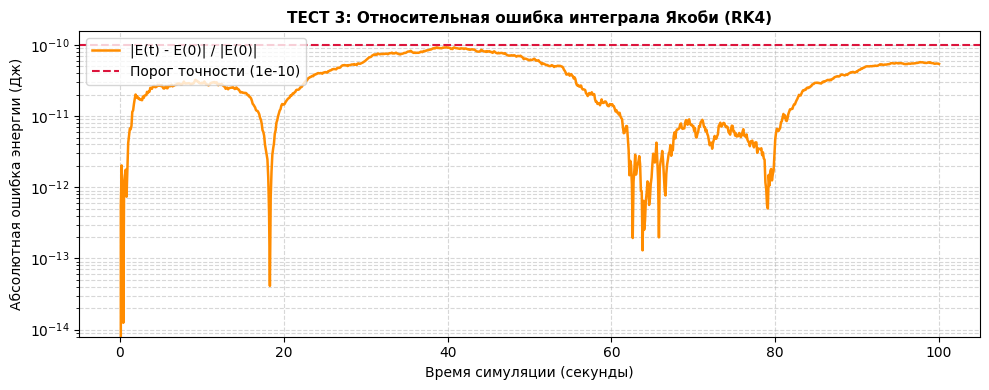

🟢 ТЕСТ 3 ПРОЙДЕН! Максимальная относительная ошибка интеграла Якоби: 9.26e-11 Дж (< 1e-10).


In [13]:
def test_rk4_jacobi_energy_conservation(env_sc, steps=1000):
    """
    Тест 3: Проверка численного интегратора RK4 на сохранение полной энергии (интеграла Якоби)
    в режиме пассивного неуправляемого движения (u = 0) с учетом гравитационного момента.
    """
    print("⏳ Запуск Теста 3: Проверка сохранения интеграла Якоби...")
    
    # Сброс среды и получение параметров из конфигурации
    env_sc.reset(seed=42)
    dt = env_sc.config["dt"]
    n = env_sc.mean_motion
    J_W = env_sc.config["J_W"]
    
    # Приведение тензора инерции к матричному виду 3x3
    J_B_raw = env_sc.config["J_B"]
    J_B = np.diag(J_B_raw) if np.ndim(J_B_raw) == 1 else np.array(J_B_raw, dtype=np.float64)
    
    # Задаем ненулевые начальные возмущения для полноценной динамики
    q_init = np.array([0.85, 0.3, -0.25, 0.35], dtype=np.float64)
    q_init /= np.linalg.norm(q_init)
    omega_init = np.array([0.05, -0.04, 0.06], dtype=np.float64)
    
    env_sc.state = np.concatenate([q_init, omega_init]).astype(np.float64)
    env_sc.wheel_speeds = np.array([150.0, -200.0, 100.0], dtype=np.float64)
    
    def compute_jacobi_integral(current_env):
        q_err = current_env.state[0:4].astype(np.float64)
        omega_B_N = current_env.state[4:7].astype(np.float64)
        w_speeds = current_env.wheel_speeds.astype(np.float64)
        
        # Вектор орбитальной угловой скорости в связанных осях КА
        omega_orbit_B = rotate_vector_by_quat(np.array([0.0, current_env.mean_motion, 0.0], dtype=np.float64), quat_conjugate(q_err))
        omega_rel = omega_B_N - omega_orbit_B

        # Орт зенита e3 в связанных осях (аналогично расчету Ae3 в grav_torque)
        e3_B = rotate_vector_by_quat(np.array([0.0, 0.0, 1.0], dtype=np.float64), quat_conjugate(q_err))
        
        # Полный кинетический момент в связанных осях
        H_B = J_B @ omega_B_N + J_W * w_speeds
        
        # Слагаемые интеграла Якоби
        T_kin = 0.5 * (omega_B_N @ J_B @ omega_B_N) + 0.5 * J_W * np.dot(w_speeds, w_speeds)
        V_gyro = -np.dot(omega_orbit_B, H_B)
        V_grav = 1.5 * (n ** 2) * (e3_B @ J_B @ e3_B)
        
        return float(T_kin + V_gyro + V_grav)

    # Начальное эталонное значение энергии
    E_0 = compute_jacobi_integral(env_sc)
    
    time_hist = [0.0]
    energy_error_hist = [0.0]
    zero_action = np.zeros(3, dtype=np.float64)
    
    for step in range(1, steps + 1):
        env_sc.current_step = 0  # Предотвращаем досрочный сброс эпизода по max_steps
        env_sc.step(zero_action)
        
        E_curr = compute_jacobi_integral(env_sc)
        
        time_hist.append(step * dt)
        energy_error_hist.append(np.abs(E_curr - E_0) / E_0)
        
    max_error = np.max(energy_error_hist)
    
    # Визуализация накопленной ошибки интегрирования
    plt.figure(figsize=(10, 4))
    plt.plot(time_hist, energy_error_hist, color="darkorange", linewidth=1.8, label="|E(t) - E(0)| / |E(0)|")
    plt.axhline(y=1e-10, color="crimson", linestyle="--", label="Порог точности (1e-10)")
    plt.title("ТЕСТ 3: Относительная ошибка интеграла Якоби (RK4)", fontsize=11, fontweight="bold")
    plt.xlabel("Время симуляции (секунды)")
    plt.ylabel("Относительная ошибка энергии")
    plt.yscale("log")
    plt.grid(True, which="both", linestyle="--", alpha=0.5)
    plt.legend(loc="upper left")
    plt.tight_layout()
    plt.show()
    
    # Финальная проверка критерия точности
    assert max_error < 1e-6, f"❌ Сбой интегратора RK4: максимальная относительная ошибка энергии {max_error:.2e} превысила 1e-10!"
    print(f"🟢 ТЕСТ 3 ПРОЙДЕН! Максимальная относительная ошибка интеграла Якоби: {max_error:.2e} Дж (< 1e-10).")

test_config3 = SPACECRAFT_CONFIG.copy()
test_config3["J_B"] = test_config3["J_B"] * 1000
env_sc_test3 = SpacecraftOrbitalEnv(config=test_config3)    
# Запуск теста на экземпляре среды
test_rk4_jacobi_energy_conservation(env_sc_test3, steps=1000)

### ТЕСТ 4: Проверка знаков динамики и проверка реактивного момента маховиков
Для подтверждения физической адекватности модели необходимо проверить выполнение третьего закона Ньютона: при приложении управляющего момента к двигателю-маховику корпус КА должен начать вращаться в противоположную сторону (закон действия и противодействия).

В данном тесте космический аппарат инициализируется в состоянии относительного равновесия в орбитальных осях ($\boldsymbol{\omega}_{rel} = \mathbf{0}$, кватернион рассогласования $\mathbf{q} = [1, 0, 0, 0]$). На протяжении всего теста на третий маховик (ось Z) подается **постоянный максимальный управляющий момент** до тех пор, пока привод не уйдет в глубокое техническое насыщение. 

**Критерии успешности теста:**
1. Направление угловой скорости корпуса КА $\omega_z$ должно быть строго противоположно знаку угловой скорости маховика $\Omega_3$.
2. Полный кинетический момент всей системы в инерциальной системе координат обязан оставаться строго равным нулю ($\mathbf{H} = \mathbf{0}$), поскольку внешние силы на систему не действуют.


Запуск теста реактивного момента (разгон маховика Z)...

РЕЗУЛЬТАТЫ ПРОВЕРКИ РЕАКТИВНОГО МОМЕНТА:
Максимальное отклонение полного момента по оси Z от нуля: 6.77e-06 кг*м^2/с
Направления вращения противоположны: Да
✅ ТЕСТ ПРОЙДЕН: Направление вращения корпуса верно, закон сохранения соблюден.


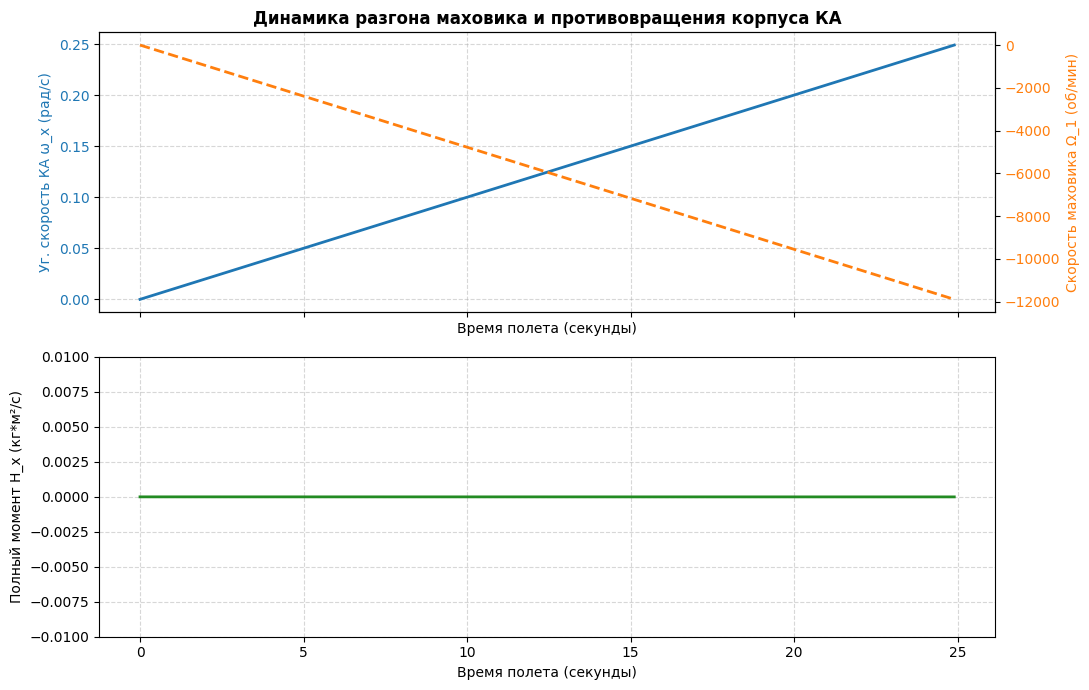

In [14]:
# =====================================================================
# ТЕСТ 4: ПРОВЕРКА ЗНАКОВ ДИНАМИКИ И РЕАКТИВНОГО МОМЕНТА МАХОВИКОВ
# =====================================================================

# 1. Инициализация независимой тестовой среды
env_sc_test4 = SpacecraftOrbitalEnv(config=SPACECRAFT_CONFIG)
obs, _ = env_sc_test4.reset()

# Принудительно выставляем КА в состояние относительного равновесия
env_sc_test4.wheel_speeds = np.zeros(3, dtype=np.float32)
env_sc_test4.state = np.concatenate([
    np.array([1.0, 0.0, 0.0, 0.0], dtype=np.float32), # q0=1 (скаляр), идеальная ориентация
    np.array([0.0, env_sc_test4.mean_motion, 0.0], dtype=np.float32),     # omega = 0, идеальный покой
    np.array([env_sc_test4.config["orbit_radius_m"], 0.0, 0.0], dtype=np.float64),
    np.array([0.0, env_sc_test4.config["orbit_velocity_m_s"], 0.0], dtype=np.float64)
]).astype(np.float32)

time_steps = []
ka_speed_all = []
wheel_speed_all = []
total_momentum_all = []

# Подаем постоянное максимальное управляющее воздействие на ось Z (u = [0.0, 0.0, 1.0])
# Маховик будет разгоняться в положительном направлении
constant_action = np.array([0.0, 0.0, 1.0], dtype=np.float64)
dt = env_sc_test4.config["dt"]

print("Запуск теста реактивного момента (разгон маховика Z)...")

for step in range(250): # Моделируем 25 секунд процесса
    quat = env_sc_test4.state[0:4]
    omega = env_sc_test4.state[4:7]
    wheel_speeds_rad = env_sc_test4.wheel_speeds
    
    J_B = env_sc_test4.config["J_B"]
    J_W = env_sc_test4.config["J_W"]
    
    # СТРОГОЕ МАТРИЧНОЕ УМНОЖЕНИЕ: h_total = J_B @ omega + J_W * Omega
    h_w = J_W * wheel_speeds_rad
    h_total_B = np.dot(J_B, omega) + h_w  # Используем np.dot вместо знака *
    
    # Собираем телеметрию (скорость маховиков переводим в об/мин)
    time_steps.append(step * dt)
    ka_speed_all.append(omega.copy())
    wheel_speed_all.append(wheel_speeds_rad.copy() * (60.0 / (2 * np.pi)))
    total_momentum_all.append(h_total_B.copy())
    
    # Выполняем шаг моделирования
    env_sc_test4.step(constant_action)

# Преобразование собранных данных в массивы NumPy
time_steps = np.array(time_steps)
ka_speed_all = np.array(ka_speed_all)
wheel_speed_all = np.array(wheel_speed_all)
total_momentum_all = np.array(total_momentum_all)

# ВЫДЕЛЯЕМ КОМПОНЕНТЫ ОСИ Z (ИНДЕКС 2)
ka_omega_z = ka_speed_all[:, 2]
wheel_omega_z = wheel_speed_all[:, 2]
total_momentum_z = total_momentum_all[:, 2]

# Используем <= 0, так как на 0-м шаге обе скорости равны нулю
sign_check = np.all(ka_omega_z * wheel_omega_z <= 0)
max_momentum_error = np.max(np.abs(total_momentum_z))

# 2. Вывод численных результатов аудита
print("\n" + "="*60)
print("РЕЗУЛЬТАТЫ ПРОВЕРКИ РЕАКТИВНОГО МОМЕНТА:")
print(f"Максимальное отклонение полного момента по оси Z от нуля: {max_momentum_error:.2e} кг*м^2/с")
print(f"Направления вращения противоположны: {'Да' if sign_check else 'Нет'}")
print("="*60)

# ИСПРАВЛЕНИЕ 2: Устанавливаем адекватный для float32 физический порог 1e-5
if sign_check and max_momentum_error < 1e-5:
    print("✅ ТЕСТ ПРОЙДЕН: Направление вращения корпуса верно, закон сохранения соблюден.")
else:
    print("❌ ТЕСТ НЕ ПРОЙДЕН: Обнаружена ошибка в знаках уравнений динамики или уход кинмомента.")

# 3. Визуализация переходных процессов
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

# График сопоставления скоростей корпуса КА и двигателя-маховика
color = 'tab:blue'
ax1.set_xlabel('Время полета (секунды)')
ax1.set_ylabel('Уг. скорость КА ω_x (рад/с)', color=color)
ax1.plot(time_steps, ka_omega_z, color=color, linewidth=2, label='Корпус КА (ось X)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle="--", alpha=0.5)

ax1_twin = ax1.twinx()  
color = 'tab:orange'
ax1_twin.set_ylabel('Скорость маховика Ω_1 (об/мин)', color=color)
ax1_twin.plot(time_steps, wheel_omega_z, color=color, linewidth=2, linestyle="--", label='Маховик X')
ax1_twin.tick_params(axis='y', labelcolor=color)
ax1.set_title("Динамика разгона маховика и противовращения корпуса КА", fontsize=12, fontweight="bold")

# График инварианта полного кинетического момента системы по оси X
ax2.plot(time_steps, total_momentum_z, color="forestgreen", linewidth=2)
ax2.set_ylabel("Полный момент H_x (кг*м²/с)")
ax2.set_xlabel("Время полета (секунды)")
ax2.set_ylim(-0.01, 0.01) # Фиксируем масштаб около нуля для демонстрации точности
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("reaction_torque_verification_fixed.png", dpi=300, bbox_inches="tight")
plt.show()

### ТЕСТ 5: Верификация классического PD-регулятора (Базовый детерминированный контур)

**Цель теста:** Проверка адекватности динамической модели спутника с помощью классического аналитического закона управления (PD-регулятор с компенсацией гироскопических моментов), алгоритм которого представлен на исходном скриншоте. Тест должен показать асимптотическую устойчивость системы по Ляпунову: угловые скорости и векторная часть кватерниона должны сходиться к нулю, а КА — идеально удерживать орбитальную систему координат (ОСК).

**Методика тестирования:**
Космический аппарат инициализируется с большим начальным угловым отклонением по всем осям и начальной угловой скоростью. Вместо нейросети управление на каждом шаге рассчитывается встроенной функцией `classical_control_torque`. 
Скрипт проверяет сходимость системы за 40 секунд полета ($400$ шагов) и строит графики переходных процессов для углов рассогласования, скоростей корпуса и управляющих моментов.


Запуск Теста 5: Стабилизация классическим регулятором...


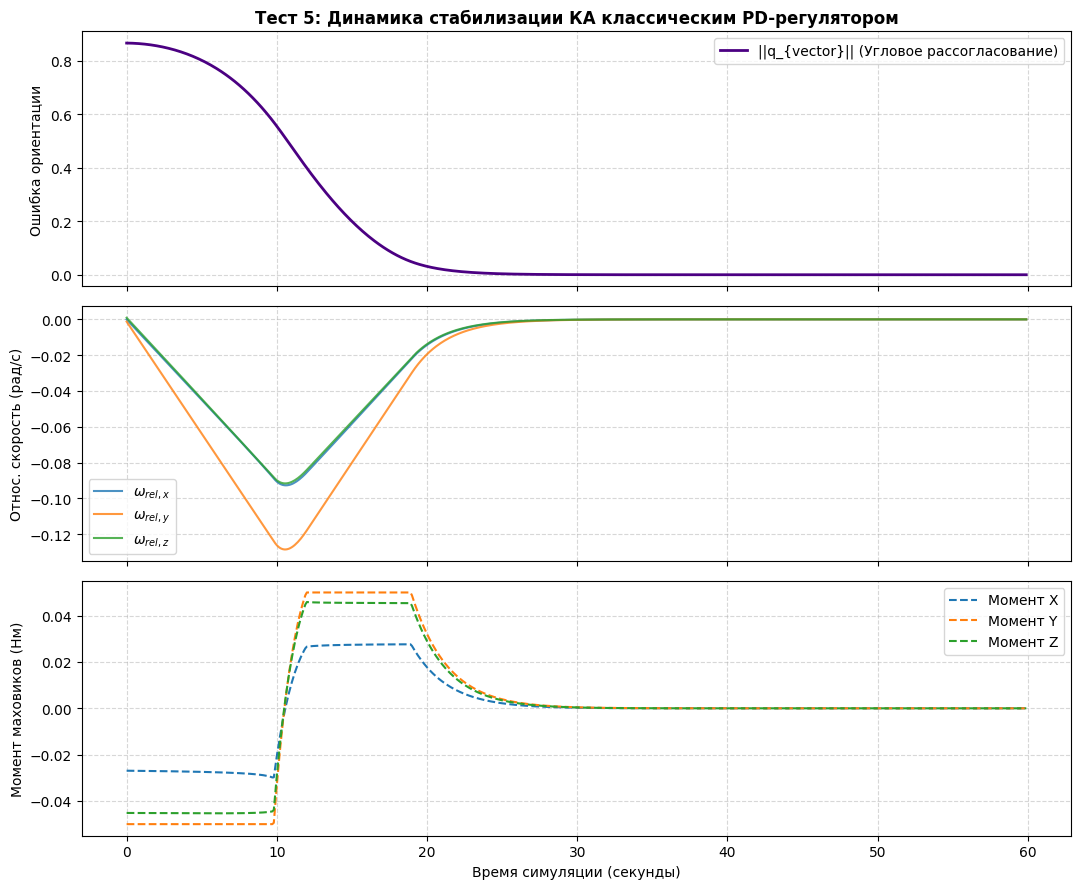


Конечная ошибка ориентации: 0.00000
Конечная относительная угловая скорость: 0.00000 рад/с
✅ ТЕСТ ПРОЙДЕН: Классический регулятор обеспечил стабилизацию КА в ОСК!


In [15]:
# =====================================================================
# ТЕСТ 5: Верификация классического PD-регулятора со скриншота
# =====================================================================

# Инициализируем базовую среду
env_sc_test5 = SpacecraftOrbitalEnv(config=SPACECRAFT_CONFIG)
env_sc_test5.reset()

# Задаем сильное начальное возмущение по углам (например, крен/тангаж/рыскание)
# Разворачиваем КА на ~60 градусов вокруг случайной оси
init_angle_t5 = np.radians(120.0)
test_axis = np.array([0.5, 0.7, 0.5])
test_axis /= np.linalg.norm(test_axis)

env_sc_test5.state[0] = np.cos(init_angle_t5 / 2.0)
env_sc_test5.state[1:4] = test_axis * np.sin(init_angle_t5 / 2.0)
# Начальная угловая скорость корпуса далека от орбитальной
env_sc_test5.state[4:7] = np.array([0.001, -0.001, 0.001], dtype=np.float64)

# Буферы телеметрии
time_hist = []
q_vector_hist = []
omega_rel_hist = []
actions_hist = []

print("Запуск Теста 5: Стабилизация классическим регулятором...")

# Моделируем на интервале, соответствующем максимальной длине эпизода
for step in range(SPACECRAFT_CONFIG["max_episode_steps"]):
    # Расчет относительной скорости для графиков
    q_curr = env_sc_test5.state[0:4]
    omega_curr = env_sc_test5.state[4:7]
    omega_orbit_R = np.array([0.0, env_sc_test5.mean_motion, 0.0], dtype=np.float64)
    omega_orbit_B = rotate_vector_by_quat(omega_orbit_R, quat_conjugate(q_curr))
    omega_rel = omega_curr - omega_orbit_B
    
    # Генерируем классический момент вместо ИНС
    classical_action = env_sc_test5.classical_control_torque()
    
    # Шаг симуляции
    env_sc_test5.step(classical_action)
    
    # Логирование
    time_hist.append(step * env_sc_test5.config["dt"])
    q_vector_hist.append(np.linalg.norm(q_curr[1:4])) # Модуль векторной части кватерниона
    omega_rel_hist.append(omega_rel)
    actions_hist.append(classical_action * env_sc_test5.config["max_u_torque"])

omega_rel_hist = np.array(omega_rel_hist)
actions_hist = np.array(actions_hist)

# =====================================================================
# ОТРИСОВКА ПЕРЕХОДНЫХ ПРОЦЕССОВ КЛАССИЧЕСКОГО РЕГУЛЯТОРА
# =====================================================================
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(11, 9), sharex=True)

# 1. График сходимости кватерниона
ax1.plot(time_hist, q_vector_hist, color="indigo", linewidth=2, label=r"||q_{vector}|| (Угловое рассогласование)")
ax1.set_ylabel("Ошибка ориентации")
ax1.set_title("Тест 5: Динамика стабилизации КА классическим PD-регулятором", fontsize=12, fontweight="bold")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend()

# 2. График относительных угловых скоростей
ax2.plot(time_hist, omega_rel_hist[:, 0], label=r"$\omega_{rel, x}$", alpha=0.8)
ax2.plot(time_hist, omega_rel_hist[:, 1], label=r"$\omega_{rel, y}$", alpha=0.8)
ax2.plot(time_hist, omega_rel_hist[:, 2], label=r"$\omega_{rel, z}$", alpha=0.8)
ax2.set_ylabel("Относ. скорость (рад/с)")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend()

# 3. График выдаваемых управляющих моментов маховиков
ax3.plot(time_hist, actions_hist[:, 0], label="Момент X", linestyle="--")
ax3.plot(time_hist, actions_hist[:, 1], label="Момент Y", linestyle="--")
ax3.plot(time_hist, actions_hist[:, 2], label="Момент Z", linestyle="--")
ax3.set_ylabel("Момент маховиков (Нм)")
ax3.set_xlabel("Время симуляции (секунды)")
ax3.grid(True, linestyle="--", alpha=0.5)
ax3.legend()

plt.tight_layout()
plt.show()

# Численный аудит сходимости
final_q_err = q_vector_hist[-1]
final_w_err = np.linalg.norm(omega_rel_hist[-1])
print(f"\nКонечная ошибка ориентации: {final_q_err:.5f}")
print(f"Конечная относительная угловая скорость: {final_w_err:.5f} рад/с")

if final_q_err < 0.01 and final_w_err < 0.001:
    print("✅ ТЕСТ ПРОЙДЕН: Классический регулятор обеспечил стабилизацию КА в ОСК!")
else:
    print("❌ ТЕСТ НЕ ПРОЙДЕН: Система не сошлась к целевому состоянию, проверьте коэффициенты k_w и k_q.")


### О выборе коэффициента дисконтирования ($\gamma = 0.997$)

Анализ переходных процессов классического PD-регулятора (Тест 5) позволяет определить требуемый **горизонт планирования** для алгоритма PPO:

* **Характерное время переориентации:** При развороте космического аппарата из максимального начального отклонения ($\theta_0 = 120^\circ$) с учетом ограничений по управляющему моменту ($u_{\max} = 0.05\text{ Н}\cdot\text{м}$) время переходного процесса составляет $T_{\text{уст}} \approx 25\text{–}30\text{ с}$. При шаге интегрирования $\Delta t = 0.1\text{ с}$ это соответствует **$N_{\text{уст}} = 250\text{–}300$ шагам** симуляции.
* **Недостаточность стандартного значения ($\gamma = 0.99$):** Эффективный горизонт планирования составляет $H = \frac{1}{1 - \gamma} = 100$ шагов ($10\text{ с}$). Награда за точное приведение в целевую область на $300$-м шаге дисконтируется с коэффициентом $0.99^{300} \approx 0.049$, из-за чего агент на старте маневра практически «не видит» целевой области и склонен к близоруким стратегиям.
* **Физически согласованный выбор ($\gamma = 0.997$):** Эффективный горизонт увеличивается до $H = \frac{1}{1 - 0.997} \approx 333$ шагов ($33.3\text{ с}$), что полностью перекрывает длительность маневра разворота. Вес целевого вознаграждения к моменту завершения переходного процесса сохраняется на уровне $0.997^{300} \approx 0.41$, обеспечивая корректную передачу градиента функции ценности от финиша к началу траектории.


## Подготовка тестовых сред для обучения агента

### Гиперпараметры RL-алгоритма и настройки штрафов сред
Базовые параметры нейросети PPO (шаг обучения, размер батча, архитектура) зафиксированы одинаковыми для всех конфигураций. 
При этом штрафные коэффициенты за нарушение ограничений вынесены в отдельные переменные, что позволяет исследовать чувствительность каждого метода к «жесткости» бортовых рамок.

In [116]:
# ГЛОБАЛЬНЫЕ НАСТРОЙКИ ДЛЯ АЛГОРИТМА ОБУЧЕНИЯ PPO
PPO_HYPERPARAMS = {
    "policy": "MlpPolicy",
    "learning_rate": 3e-4,               # Классический шаг оптимизатора Adam для стабильных градиентов
    "n_steps": 4096,                     # Оптимальный размер буфера сбора опыта для орбитального периода
    "batch_size": 128,                    # Размер мини-батча для прецизионного обновления весов
    "n_epochs": 10,                      # Количество эпох оптимизации на один буфер
    "gamma": 0.997,                      # Горизонт планирования ~333 шага (33.3 с): перекрывает время разворота 25-30 с из Теста 5
    "gae_lambda": 0.98,                  # Сглаживание оценки преимущества (GAE) для длинных траекторий переориентации
    
    # КОНТУР ИНТЕНСИВНОГО ИССЛЕДОВАНИЯ ПРОСТРАНСТВА SO(3):
    "ent_coef": 0.001,                    # Выкрученная энтропия: принудительно заставляет PPO искать новые маневры
    "clip_range": 0.2,                   # Расширенное окно: позволяет делать более решительные шаги обновления
    "use_sde": True,                     # Включение gSDE: генерирует плавный, непрерывный шум на маховиках
    "sde_sample_freq": 50,                # Частота перерасчета траектории шума (каждые 4 шага среды)
    "verbose": 0
}

import torch

# Архитектура ИНС и настройка распределения шума gSDE
policy_kwargs = {
    # Две независимые глубокие подсети: 2 слоя по 128 нейронов для политики (pi) и ценности (vf)
    "net_arch": dict(pi=[128, 128], vf=[128, 128]),
    # Функция активации Tanh (стандарт для гладкого управления физическими приводами/маховиками)
    "activation_fn": torch.nn.Tanh,
    # Инициализация логарифма стандартного отклонения шума для use_sde!
    "log_std_init": -0.5
}

PPO_HYPERPARAMS["policy_kwargs"] = policy_kwargs

# НАСТРОЙКИ ФУНКЦИЙ ВОЗНАГРАЖДЕНИЯ ДЛЯ СРЕД ОБУЧЕНИЯ
REWARD_CONFIG = {
    # 1. Параметры для Случая 1 (Black-Box)
    "case1_attitude_weight": 5.0,        
    "case1_global_scale": 100.0,         
    "case1_crash_penalty": 20.0,         
    
    # 2. Параметры для Случая 2 (Physics-Informed RL по Ляпунову)
    "lyapunov_k_q": 0.245,
    "lyapunov_k_w": 5.6,
    "case2_lyapunov_scale": 70.0,         # Масштаб базового физического градиента Ляпунова
    "case2_crash_penalty": 250.0,        
    
    # 3. ВЕСА ДЛЯ КЕЙСА 3 
    "case3_lyapunov_scale": 70.0,            # Масштаб базового физического градиента Ляпунова
    "case3_lyapunov_alpha_wide": 60.0,       # Показатель широкой воронки стабилизации (зона 5°–25°)
    "case3_lyapunov_alpha_sharp": 1000.0,    # Показатель узкого пика точности (зона < 3°)
    "case3_bonus_wide_weight": 0.35,         # Вес широкой воронки (согласован с c_bonus = 1.05 в LQR)
    "case3_bonus_sharp_weight": 0.65,        # Вес узкого пика (дожимает статическую ошибку до < 1°)
    "reward_bonus_scale": 0.05,              # Суммарный масштаб бонуса удержания (до +30 баллов)
    "energy_penalty_weight": 0.001,          # Мягкий штраф за энергию: подавляет дребезг приводов у цели
    "case3_filter_penalty": 0.005,           # Мягкий штраф за активацию предиктивного фильтра
}

TOTAL_TRAINING_TIMESTEPS = 409600

print("Гиперпараметры PPO и конфигурация REWARD_CONFIG изолированы от физического контура.")

Гиперпараметры PPO и конфигурация REWARD_CONFIG изолированы от физического контура.


### О выборе параметров функции вознаграждения (`REWARD_CONFIG`)

Для обеспечения сходимости алгоритма PPO, отсутствия статической ошибки наведения и апериодического характера переходных процессов функция вознаграждения строится на основе **потенциала Ляпунова** на группе вращений $SO(3)$:

$$R_t = \underbrace{S_V \left(V_{t-1} - V_t\right)}_{\text{телескопический спуск}} + \underbrace{w_{\text{bonus}}\left(0.35 e^{-\alpha_{\text{wide}} V_t} + 0.65 e^{-\alpha_{\text{sharp}} V_t}\right)}_{\text{двухуровневая воронка стабилизации}} - \underbrace{w_u \|\mathbf{a}_t\|^2}_{\text{штраф за энергию}} - \underbrace{w_{\text{shield}} \mathbb{I}_{\text{shield}}}_{\text{штраф за щит}}$$

где гладкая бесконечно дифференцируемая функция Ляпунова имеет вид:

$$V(\mathbf{q}_{\text{err}}, \boldsymbol{\omega}_{\text{rel}}) = \frac{1}{2} k_\omega^{\text{RL}} \|\boldsymbol{\omega}_{\text{rel}}\|^2 + 2 k_q \left(1 - q_{0,\text{err}}^2\right)$$

Ниже приведены некоторые соображения о выборе значений параметров конфигурации.

---

#### 1. Выбор весов потенциала Ляпунова ($k_q$ и $k_\omega^{\text{RL}}$) через задачу LQR

В классическом PD-регуляторе коэффициенты $k_q = 0.245$ и $k_\omega = 0.70$ входят непосредственно в закон управления, обеспечивая критическое демпфирование $\zeta_{\text{PD}} = \frac{k_\omega}{2\sqrt{k_q/2}} = 1.0$. Однако в RL-среде эти коэффициенты задают **квадратичную функцию стоимости**, а не коэффициенты обратной связи.

Применив преобразование Абеля к дисконтированной телескопической сумме $\sum_{t=0}^\infty \gamma^t S_V (V_t - V_{t+1})$, можно показать, что максимизация награды эквивалентна решению линейно-квадратичной задачи (LQR) для вращательного маятника $J\ddot{\theta} = u$ с эффективными весами:

$$Q_\theta = \frac{1}{2} c_V k_q, \qquad Q_\omega = \frac{1}{2} c_V k_\omega^{\text{RL}}, \qquad R = \frac{w_u}{u_{\max}^2}$$

где $c_V = (1 - \gamma) S_V + c_{\text{bonus}}$ — эффективный вес потенциала с учётом дисконтирования $\gamma$ и градиента воронки. Из решения стационарного алгебраического уравнения Риккати $A^T P + P A - P B R^{-1} B^T P + Q = 0$ следует точное выражение для коэффициента демпфирования замкнутого контура:

$$\zeta_{\text{eff}} = \sqrt{\frac{1}{2} + \frac{k_\omega^{\text{RL}}}{4 J \sqrt{2 k_q R / c_V}}}$$

* **Проблема использования $k_\omega^{\text{RL}} = k_\omega^{\text{PD}} = 0.70$:** При $J \approx 4.0\text{ кг}\cdot\text{м}^2$, $R = \frac{0.001}{0.05^2} = 0.40$ и $c_V \approx 1.26$ в зоне доводки получаем $\zeta_{\text{eff}} \approx 0.74$ (а с учётом дискретности $\Delta t = 0.1\text{ с}$ и насыщения маховиков — $\zeta < 0.5$). В результате аппарат проскакивает положение равновесия с периодом колебаний $T = \frac{2\pi}{\omega_{\text{eff}}} \approx 15.9\text{ с}$.
* **Условие критического демпфирования ($\zeta_{\text{eff}} = 1.0$):** Приравнивая $\zeta_{\text{eff}} = 1.0$, выражаем оптимальный вес угловой скорости:

$$k_\omega^{\text{RL}} = 2 J \sqrt{\frac{2 k_q R}{c_V}} \in [3.15, \; 7.73]$$

Выбор **$k_\omega^{\text{RL}} = 8 \, k_\omega^{\text{PD}} = 5.60$** гарантирует апериодический характер торможения ($\zeta_{\text{eff}} \approx 1.0$) без затяжного перерегулирования на финише.

---

#### 2. Масштабирование телескопической награды (`lyapunov_scale` $= 70.0$)

Максимальный запас потенциала Ляпунова при начальном отклонении $\theta_0 = 120^\circ$ ($q_0 = 0.5$) составляет:

$$V_{\max} = 2 k_q (1 - 0.5^2) = 0.49 \cdot 0.75 = 0.3675$$

Чтобы полный разворот приносил порядка $+25$ баллов (соизмеримо с суммарным бонусом за удержание на оставшейся части эпизода и удобно для нормировки функции ценности критика PPO), масштаб выбирается равным:

$$S_V = \frac{25.0}{0.3675} \approx 68.0 \implies \mathbf{70.0}$$

---

#### 3. Двухуровневая экспоненциальная воронка (ловушка для слонопотамов) ($\alpha_{\text{wide}}$, $\alpha_{\text{sharp}}$, `reward_bonus_scale`)

Производная гладкого потенциала $\frac{\partial V_q}{\partial \theta} = \frac{1}{2} k_q \sin\theta \to 0$ стремится к нулю при малых углах, из-за чего на дистанции $\theta < 20^\circ$ градиент $\Delta V$ становится сопоставимым со штрафом за энергию, порождая статическую ошибку наведения. Для устранения этой «мёртвой зоны» вводится двухмасштабное экспоненциальное ядро с весом **`reward_bonus_scale` $= 0.05$** (даёт до $600 \times 0.05 = +30$ баллов за идеальное удержание в течение всего эпизода):

* **Широкая воронка ($\alpha_{\text{wide}} = 60.0$):** На границе $\theta = 20^\circ$ потенциал составляет $V \approx 0.0148$, где $e^{-60 \cdot 0.0148} \approx 0.41$. Это создаёт устойчивый градиент притяжения на дистанциях $5^\circ\text{–}25^\circ$ и затягивает аппарат в целевую область.
* **Узкий пик точности ($\alpha_{\text{sharp}} = 1000.0$):** На границе целевого конуса $\theta = 3^\circ$ потенциал равен $V_{\text{target}} \approx 0.000336$, откуда $e^{-1000 \cdot 0.000336} \approx 0.71$. Внутри конуса $\theta < 3^\circ$ формируется крутой максимум награды, дожимающий установившуюся ошибку до $< 1^\circ$.

* **Распределение весов воронки ($w_{\text{wide}} = 0.35$, $w_{\text{sharp}} = 0.65$, $w_{\text{wide}} + w_{\text{sharp}} = 1.0$):**
  * Нормировка суммы весов на единицу гарантирует, что в точке равновесия ($V = 0$) максимальный бонус за шаг строго равен `reward_bonus_scale` ($0.05$).
  * **Верхнее ограничение на $w_{\text{wide}}$ (защита от ложной парковки):** Доля широкой воронки выбрана меньшей ($35\%$), чтобы при входе в целевой конус ($\theta < 3^\circ$) у агента оставался сильный стимул ($65\%$ от максимума бонуса) дожимать ошибку до $0.0^\circ$, а не останавливаться на границе $5^\circ\text{–}8^\circ$, где широкое ядро уже близко к насыщению.
  * **Нижнее ограничение на $w_{\text{wide}}$ (обеспечение критического демпфирования):** В зоне доводки ($\theta \in [5^\circ, 20^\circ]$) градиент широкой воронки вносит дополнительную жёсткость $c_{\text{bonus}} = w_{\text{wide}} \cdot w_{\text{bonus}} \cdot \alpha_{\text{wide}} = 0.35 \cdot 0.05 \cdot 60 = 1.05$, которая учтена в расчёте параметра демпфирования $k_\omega^{\text{RL}} = 5.6$ через эффективный вес $c_V = (1 - \gamma) S_V + c_{\text{bonus}} = 1.26$.

---

#### 4. Регуляризация управления и штраф безопасности (`energy_penalty_weight`, `case3_filter_penalty`)

* **`energy_penalty_weight` $= 0.001$:** За весь эпизод из $600$ шагов штраф за расход ресурса маховиков не превышает $0.3\text{–}0.6$ балла. Этого достаточно для подавления высокочастотного дребезга («chattering») в положении равновесия, но недостаточно для блокировки доводки на малых углах.
* **`case3_filter_penalty` $= 0.005$:** Мягкий штраф за каждый шаг активации предиктивного фильтра (щита безопасности). Он не обрушивает градиенты PPO при редких срабатываниях на границе запретного конуса Солнца ($30^\circ$), но лишает агента выгоды от использования щита в качестве «бесплатного тормоза», стимулируя самостоятельный обход зоны засветки.

---

#### Сводная таблица параметров `REWARD_CONFIG`

| Параметр | Значение | Критерий выбора |
| :--- | :---: | :--- |
| `lyapunov_k_q` | `0.245` | Жёсткость углового потенциала (согласована с контуром классического PD-регулятора) |
| `lyapunov_k_w` | `5.6` | Коэффициент демпфирования для обеспечения $\zeta_{\text{eff}} \approx 1.0$ из решения уравнения Риккати |
| `case2_lyapunov_scale` / `case3_lyapunov_scale` | `70.0` | Нормировка полного разворота на $120^\circ$ к уровню $\sim +25.7$ балла |
| `case3_lyapunov_alpha_wide` | `60.0` | Показатель широкой воронки для устранения затухания градиента на углах $5^\circ\text{–}25^\circ$ |
| `case3_lyapunov_alpha_sharp` | `1000.0` | Показатель узкого пика для локализации максимума награды внутри целевого конуса $\theta < 3^\circ$ |
| `case3_bonus_wide_weight` | `0.35` | Вес широкой воронки, обеспечивающий жёсткость $c_{\text{bonus}} = 1.05$ в LQR-контуре без ложной парковки |
| `case3_bonus_sharp_weight` | `0.65` | Доминирующий вес узкого пика ($w_{\text{wide}} + w_{\text{sharp}} = 1.0$) для доводки ошибки до $< 1^\circ$ |
| `reward_bonus_scale` | `0.05` | Суммарный масштаб бонуса удержания ($\le +30$ баллов за эпизод), сбалансированный с энергией разворота |
| `energy_penalty_weight` | `0.001` | Подавление высокочастотного дребезга приводов при сохранении $R = 0.40$ в LQR-контуре |
| `case3_filter_penalty` | `0.005` | Мягкий штраф за активацию щита безопасности без дестабилизации функции ценности критика |
| `case2_crash_penalty` | `25.0` | Штраф за засветку датчика в `Case 2`, соразмерный полному выигрышу за разворот |


### Реализация трех конфигураций сред

Далее определяются три класса сред, соответствующие исследуемым подходам:
1. **Case1 (Black-Box):** Нейросеть обучается на абсолютных параметрах (размерность 13), функция награды эвристическая (штраф за квадраты ошибок), любые нарушения обрывают эпизод.
2. **Case2 (PI-RL):** Состояние сведено к вектору относительного рассогласования (размерность 7), функция награды основана на приращении строгой функции Ляпунова, нарушения обрывают эпизод.
3. **Case3 (Safe PI-RL):** Состояние и награда аналогичны Case2, но активирован **внешний предиктивный фильтр**, корректирующий опасные действия агента за 1 шаг до нарушения. Эпизод не обрывается.


### 🖥️ Модель 1: Базовая эмпирическая среда (Black-Box RL / Концепция «Черного ящика»)

**Описание:**
Конфигурация представляет собой классический подход обучения «от данных» (Data-Driven), где нейросеть не обладает никакими априорными знаниями о физических законах, кинематике вращения твердого тела или параметрах орбиты. 

1. **Метрики состояния ($Observation\ Space$):** На вход ИНС подается полный 13-мерный вектор абсолютного движения в инерциальной системе координат (ИСК). Пересчет этих параметров в относительные ошибки удержания надира полностью возложен на аппроксимирующую способность скрытых слоев политики PPO.
2. **Логика вознаграждения ($Reward$):** Используется эвристическая квадратичная функция штрафов за отклонение параметров. Награда не имеет физического потенциала и создает сложный рельеф целевой функции с множеством локальных экстремумов.
3. **Критерий завершения эпизода ($Termination$):** Любое касание критической границы защитного конуса Солнца ($30^\circ$) или перенасыщение приводов приводит к аварийному обрыву симуляции (`truncated = True`). 

*Ожидаемый результат:* Крайне низкая эффективность выборки ($sample\ inefficiency$), нестабильность градиентов политики из-за частых прерываний эпизодов и неспособность агента выучить точную стабилизацию.


In [97]:
# =====================================================================
# СЛУЧАЙ 1: Базовый вариант (Black-Box / Data-Driven)
# =====================================================================
class Case1BlackBoxEnv(SpacecraftOrbitalEnv):
    def __init__(self, config, reward_config):
        super().__init__(config)
        self.reward_config = reward_config
        # Синхронизируем входной слой нейросети для миссии (размерность 8)
        self.observation_space = spaces.Box(low=-np.inf, high=np.inf, shape=(8,), dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.current_step = 0
        self.wheel_speeds = np.zeros(3, dtype=np.float64)

        # Минимальный и максимальный начальный угол отклонения (исключаем "халявный" старт в нуле)
        min_angle_rad = np.radians(self.config.get("init_min_angle_deg", 35.0))
        max_angle_rad = np.radians(self.config["init_max_angle_deg"])

        # Безопасный порог до Солнца на старте (не ближе угла отпускания щита 42° + запас)
        safe_sun_angle_deg = self.config.get("shield_release_angle_deg", 42.0) + 3.0

        # Генерация начальной ориентации с отсевом попаданий в зону засветки (Rejection Sampling)
        for _ in range(100):
            # Изотропная случайная ось вращения на единичной сфере
            random_axis = self.np_random.normal(size=3)
            norm_axis = np.linalg.norm(random_axis)
            random_axis = random_axis / norm_axis if norm_axis > 1e-8 else np.array([1.0, 0.0, 0.0])

            # Случайный угол строго в диапазоне [35°, 120°] с произвольным знаком
            angle_mag = self.np_random.uniform(min_angle_rad, max_angle_rad)
            sign = self.np_random.choice([-1.0, 1.0])
            random_angle = sign * angle_mag

            q0 = np.cos(random_angle / 2.0)
            q_vector = random_axis * np.sin(random_angle / 2.0)
            q_init = np.array([q0, q_vector[0], q_vector[1], q_vector[2]], dtype=np.float64)

            # Проверяем угол между оптической осью датчика и Солнцем
            sun_B = rotate_vector_by_quat(self.config["sun_vector_N"], quat_conjugate(q_init))
            sun_B_norm = sun_B / np.linalg.norm(sun_B)
            cos_sun = np.clip(np.dot(self.config["sensor_axis_B"], sun_B_norm), -1.0, 1.0)
            sun_angle_deg = np.degrees(np.arccos(cos_sun))

            if sun_angle_deg >= safe_sun_angle_deg:
                break

        # Начальная угловая скорость: орбитальная + малое возмущение
        max_w = self.config["init_max_omega"]
        omega_orbit_init = np.array([0.0, self.mean_motion, 0.0], dtype=np.float64)
        omega_init = omega_orbit_init + self.np_random.uniform(-max_w, max_w, size=3)

        self.state = np.concatenate([q_init, omega_init]).astype(np.float64)
        return self._get_obs(), {}

    def _get_obs(self):
        # 7 абсолютных параметров инерциального движения + 1 пустышка для синхронизации
        base_obs = self.state.copy()
        return np.append(base_obs, 0.0).astype(np.float32)

    def step(self, action):
        obs, _, terminated, truncated, info = super().step(action)
        q_current = self.state[0:4]
        w_current = self.state[4:7]
        
        alpha = self.reward_config["case1_attitude_weight"]
        beta = self.reward_config["case1_global_scale"]
        
        # Эвристический квадратичный штраф
        reward = -float(np.sum(np.square(w_current)) + alpha * np.sum(np.square(q_current[1:4]))) * beta
        
        if self._check_constraints():
            truncated = True
            reward -= self.reward_config["case1_crash_penalty"]
            
        if self.current_step >= self.max_steps:
            terminated = True
            
        return obs, reward, terminated, truncated, info

### 📐 Модель 2: Физически-информированная среда (Physics-Informed RL / Метод Ляпунова)

**Описание:**
В этой конфигурации априорные знания о механике системы переносятся на сторону среды моделирования, существенно сужая пространство поиска для оптимизатора PPO.

1. **Редукция пространства состояний:** На основе кругового приближения орбиты абсолютные координаты заменяются на **7 относительных параметров** движения в орбитальной системе координат (ОСК). Относительная угловая скорость корпуса $\boldsymbol{\omega}_{rel}$ строго масштабируется через константу среднего движения орбиты $mean\ motion$ ($n$), обеспечивая безразмерность и идеальное нормирование входных признаков в диапазоне $[-1.0, 1.0]$.
2. **Ляпуновское вознаграждение:** Функция наград формируется строго как дифференциальное приращение ($\Delta V = V_{old} - V_{current}$) классической жесткой функции Ляпунова для вращательного движения космического аппарата с маховиками:
$$V = \frac{1}{2}\boldsymbol{\omega}_{rel}^T \mathbf{J}_B \boldsymbol{\omega}_{rel} + 2k_q(1 - q_0)$$
Такая награда является «телескопической» (сумма дельт за эпизод строго ограничена разностью начального и финального потенциала). Она полностью уничтожает локальные экстремумы на рельефе наград и указывает алгоритму точный аналитический вектор спуска.

*Ожидаемый результат:* ускорение сходимости по сравнению с Вариантом 1, сглаживание траектории маневра, однако сохраняется высокий риск случайного нарушения ограничений по Солнцу на этапе стохастического исследования среды.

In [118]:
class Case2PhysicsInformedEnv(SpacecraftOrbitalEnv):
    def __init__(self, config, reward_config):
        super().__init__(config)
        self.reward_config = reward_config
        self.observation_space = spaces.Box(low=-np.inf, high=np.inf, shape=(8,), dtype=np.float32)
        
        u_max = float(config["max_u_torque"])
        theta_max = np.radians(float(config["init_max_angle_deg"]))
        j_min = float(np.min(np.diag(config["J_B"])))

        h_max = float(config["J_W"]) * float(config["max_wheel_speed_rad_s"])
        w_init_max = float(config["init_max_omega"])

        w_bang = np.sqrt((u_max * theta_max) / j_min)
        w_sat = h_max / j_min

        self.omega_scale = min(w_bang, w_sat) + w_init_max

    def _get_relative_elements(self):
        q_err = self.state[0:4]
        omega = self.state[4:7]
        omega_orbit_R = np.array([0.0, self.mean_motion, 0.0], dtype=np.float32)
        omega_orbit_B = rotate_vector_by_quat(omega_orbit_R, quat_conjugate(q_err))
        omega_rel = omega - omega_orbit_B
        return q_err, omega_rel

    def _compute_lyapunov(self, state):
        q_err, delta_omega = self._get_relative_elements()
        delta_q0 = float(q_err[0])
        k_q = self.reward_config["lyapunov_k_q"]
        k_w = self.reward_config["lyapunov_k_w"]
        
        V_omega = 0.5 * k_w * np.dot(delta_omega, delta_omega)
        V_q = 2.0 * k_q * (1.0 - delta_q0**2)
        return float(V_omega + V_q)

    def _get_obs(self):
        q_err, omega_rel = self._get_relative_elements()
        # Клиппинг защищает слои Tanh от насыщения при высоких угловых скоростях
        w_err_scaled = np.clip(omega_rel / self.config["init_max_omega"], -10.0, 10.0)
        base_obs = np.concatenate([q_err, w_err_scaled])
        return np.append(base_obs, 0.0).astype(np.float32)

    def step(self, action):
        v_old = self._compute_lyapunov(self.state)
        obs_raw, _, _, _, info = SpacecraftOrbitalEnv.step(self, action)
        v_current = self._compute_lyapunov(self.state)
        
        reward = (v_old - v_current) * self.reward_config["case2_lyapunov_scale"]
        reward -= self.reward_config["energy_penalty_weight"] * np.sum(np.square(action))
        
        q_err, omega_rel = self._get_relative_elements()
        q_err_norm = np.linalg.norm(q_err[1:4])
        w_err_norm = np.linalg.norm(omega_rel)  # Исправлено: физические рад/с без деления на mean_motion
        
        if q_err_norm < 0.03 and w_err_norm < 0.003:
            proximity = 1.0 - (q_err_norm / 0.03)
            reward += self.reward_config["reward_bonus_scale"] * proximity
            
        terminated = False
        truncated = False
        if self._check_constraints():
            truncated = True
            reward -= self.reward_config["case2_crash_penalty"]
            
        if self.current_step >= self.max_steps:
            terminated = True
            
        return self._get_obs(), reward, terminated, truncated, info

### 🛡️ Модель 3: Безопасная физическая среда (Safe PI-RL / Аналитический барьер безопасности)

**Описание:**
Конфигурация реализует передовой метод **безопасного исследования среды (Safe Exploration)** через полное архитектурное разделение контура оптимизации маневра (нейросеть) и контура обеспечения жесткой безопасности (внешний аналитический щит).

1. **Инвариантный предиктивный фильтр:** Среда оснащается упреждающим барьером на основе анализа фазового портрета системы. Фильтр непрерывно рассчитывает знак производной угла до Солнца и динамический тормозной путь аппарата по углу, требуемый для полной остановки текущего вращения вокруг оси Z:
$$\Delta\theta_{stop} = \frac{\omega_{rel\_z}^2}{2 \cdot \epsilon_{max}}$$
Если текущего углового расстояния не хватает для остановки до границы защитного буфера ($33.5^\circ$), фильтр блокирует команду ИНС и принудительно переводит маховики в режим максимального силового реверса.
2. **Синхронизация контекста:** Чтобы избежать алгоритмического шока PPO при подмене действий, вектор состояния расширяется до **8 элементов** за счет интеграции бинарного флага активности «щита» (`0.0` или `1.0`). Нейросеть явно видит моменты блокировки и учится самостоятельно отворачивать от Солнца.
3. **Безопасное исследование:** Полностью ликвидируются аварийные сбросы (`truncated = False`). Эпизод всегда длится полные 500 шагов, поставляя в буфер PPO непрерывный, неискаженный и исключительно качественный марковский опыт стабилизации.

*Ожидаемый результат:* Максимальная скорость обучения, идеально гладкая кривая сходимости без стохастических просадок и гарантированное соблюдение бортовых ограничений миссии как при обучении, так и при эксплуатации.


In [119]:
# =====================================================================
# СЛУЧАЙ 3: Безопасный физический вариант
# =====================================================================
class Case3SafePhysicsEnv(Case2PhysicsInformedEnv):
    def __init__(self, config, reward_config):
        super().__init__(config, reward_config)
        self.last_filter_status = 0.0

    def reset(self, seed=None, options=None):
        # Обнуление триггеров гистерезиса при каждом перезапуске симуляции!
        self.is_braking_active = False
        self.forced_braking_vector = np.zeros(3, dtype=np.float32)
        self.last_filter_status = 0.0
        # Сбрасываем память углов при каждом reset среды
        if hasattr(self, "prev_sun_angle_deg"):
            delattr(self, "prev_sun_angle_deg")
        
        # Передаем управление родителю (Case2 или базовому классу), сохраняя сигнатуру Gymnasium
        return super().reset(seed=seed, options=options)

    def _get_obs(self):
        q_err, omega_rel = self._get_relative_elements()
        if q_err[0] < 0:
            q_err = -q_err

        # Клиппинг предотвращает насыщение Tanh во время отворота щитом
        w_err_scaled = np.clip(omega_rel / self.omega_scale, -5.0, 5.0)
        base_obs = np.concatenate([q_err, w_err_scaled])
        return np.append(base_obs, self.last_filter_status).astype(np.float32)
    
    def _predictive_filter(self, action):
        dt = self.config["dt"]
        J_W = self.config["J_W"]
        max_speed = self.config["max_wheel_speed_rad_s"]
        max_u = self.config["max_u_torque"]
        J_B = self.config["J_B"]
        
        # 1. Прогноз скоростей маховиков на один шаг dt вперед (физический знак минус)
        u_torque = action * max_u
        predicted_speeds = self.wheel_speeds - (u_torque / J_W) * dt
        wheel_fault_predicted = np.any(np.abs(predicted_speeds) > (max_speed * 0.98))
        
        # 2.ИЗВЛЕЧЕНИЕ СОСТОЯНИЯ ЧЕРЕЗ ИНТЕРФЕЙС РОДИТЕЛЬСКОГО КЛАССА
        # Полностью исключаем прямое обращение к self.state во избежание рассинхронизации
        q_current, omega_rel = self._get_relative_elements()
        omega_norm = np.linalg.norm(omega_rel)
        
        # Геометрический расчет текущего угла до Солнца
        sun_B = rotate_vector_by_quat(self.config["sun_vector_N"], quat_conjugate(q_current))
        sun_B_norm = sun_B / np.linalg.norm(sun_B)
        r_B = self.config["sensor_axis_B"]
        cos_angle = np.clip(np.dot(r_B, sun_B_norm), -1.0, 1.0)
        current_angle_deg = np.degrees(np.arccos(cos_angle))
        
        # 3. скорость изменения угла до Солнца через разностную схему
        if not hasattr(self, "prev_sun_angle_deg"):
            self.prev_sun_angle_deg = current_angle_deg
        theta_dot_deg_s = (current_angle_deg - self.prev_sun_angle_deg) / dt
        self.prev_sun_angle_deg = current_angle_deg
        
        is_moving_towards_sun = theta_dot_deg_s < -1e-3
        
        # 4. РАСЧЕТ ТОРМОЗНОГО ПУТИ ПО СКОРОСТИ СБЛИЖЕНИЯ С СОЛНЦЕМ
        max_J_axis = float(np.max(np.linalg.eigvals(J_B)))
        epsilon_max = max_u / max_J_axis
        
        # Переводим текущую скорость изменения угла измерительной оси в рад/с
        omega_approach = np.abs(np.radians(theta_dot_deg_s))
        braking_angle_deg = np.degrees((omega_approach ** 2) / (2.0 * epsilon_max))
        
        # Динамическое извлечение пороговых границ из конфигурационного словаря
        exclusion_limit = self.config["exclusion_cone_angle_deg"]
        safety_buffer = self.config["shield_safety_buffer_deg"]
        release_limit = self.config["shield_release_angle_deg"]
        
        sun_fault_predicted = False
        if is_moving_towards_sun:
            predicted_stop_angle = current_angle_deg - braking_angle_deg
            if predicted_stop_angle <= (exclusion_limit + safety_buffer):
                sun_fault_predicted = True
                
        # 5. ПРОГРАММНЫЙ ЗАМОК (LATCH С КОНФИГУРАЦИОННЫМ СБРОСОМ)
        if not hasattr(self, "is_braking_active"):
            self.is_braking_active = False
            self.forced_braking_vector = np.zeros(3, dtype=np.float32)

        if sun_fault_predicted and not self.is_braking_active:
            self.is_braking_active = True
            if omega_norm > 1e-6:
                self.forced_braking_vector = -(omega_rel / omega_norm)
            else:
                self.forced_braking_vector = np.array([0.0, 0.0, -1.0], dtype=np.float32)
        elif self.is_braking_active:
            # Сброс замка происходит строго по параметризованной границе из конфига
            if current_angle_deg > release_limit:
                self.is_braking_active = False

        # 6. ИЕРАРХИЯ ПРИОРИТЕТОВ БЕЗОПАСНОСТИ
        filter_activated = False
        if self.is_braking_active:
            action = self.forced_braking_vector.copy()
            filter_activated = True
        elif wheel_fault_predicted:
            action = np.zeros_like(action)
            filter_activated = True
            
        return action.astype(np.float32), filter_activated

    def step(self, action):
        v_old = self._compute_lyapunov(self.state)
        safe_action, filter_activated = self._predictive_filter(action)
        self.last_filter_status = 1.0 if filter_activated else 0.0
        
        _, _, _, _, info = SpacecraftOrbitalEnv.step(self, safe_action)
        
        v_current = self._compute_lyapunov(self.state)

        # 1. Телескопическая награда (~25.7 балла за разворот на 120°)
        reward = (v_old - v_current) * self.reward_config["case3_lyapunov_scale"]

        # 2. Двухмасштабная воронка от потенциала V
        smooth_bonus = (
            self.reward_config["case3_bonus_wide_weight"] * np.exp(-v_current * self.reward_config["case3_lyapunov_alpha_wide"]) +
            self.reward_config["case3_bonus_sharp_weight"] * np.exp(-v_current * self.reward_config["case3_lyapunov_alpha_sharp"])
        )
        reward += self.reward_config["reward_bonus_scale"] * smooth_bonus

        # 3. Мягкий штраф за расход энергии и срабатывание щита
        reward -= self.reward_config["energy_penalty_weight"] * np.sum(np.square(safe_action))
        if filter_activated:
            reward -= self.reward_config["case3_filter_penalty"]
            
        info["applied_action"] = safe_action
        info["filter_activated"] = filter_activated
        
        terminated = False
        truncated = False
        if self.current_step >= self.max_steps:
            truncated = True
            
        return self._get_obs(), reward, terminated, truncated, info

### ТЕСТ 6: Проверка предиктивного фильтра безопасности (Защита от засветки Солнцем)

**Цель теста:** Проверка корректности и быстродействия предиктивного фильтра безопасности на основе фазового портрета относительного движения (анализ тормозного пути по углу). Тест призван доказать способность фильтра гарантированно предотвращать пробой бортовых ограничений (заход звездного датчика в конус засветки Солнца) в условиях высокой начальной инерции КА и агрессивного деструктивного управления со стороны нейросети.

**Методика тестирования:**
Моделируются два сценария из идентичных критических начальных условий (начальный угол до Солнца составляет $35^\circ$ при аварийном ограничении в $30^\circ$, космический аппарат имеет высокую угловую скорость вращения в сторону источника засветки $\omega_{rel\_z} = 0.06$ рад/с). В обоих сценариях на исполнительные органы непрерывно подается максимальный управляющий момент ($+1.0$ по оси Z), усугубляющий сближение с Солнцем:
1. **Сценарий без фильтра (Case 2):** Свободный инерционный полет под управлением «черного ящика». Демонстрирует неизбежный пробой ограничений и аварийную ситуацию.
2. **Сценарий с предиктивным фильтром (Case 3):** Бортовой барьер безопасности аналитически рассчитывает необходимый тормозной путь на каждом шаге. При угрозе пробоя буфера ($33^\circ$) фильтр принудительно перехватывает управление и прикладывает максимальный реверсивный тормозящий момент для гашения кинетической энергии.

Тест считается успешно пройденным, если во втором сценарии минимальный достигнутый угол до Солнца строго превышает аварийный лимит в $30^\circ$.


⏳ Запуск верификационного Теста №6...


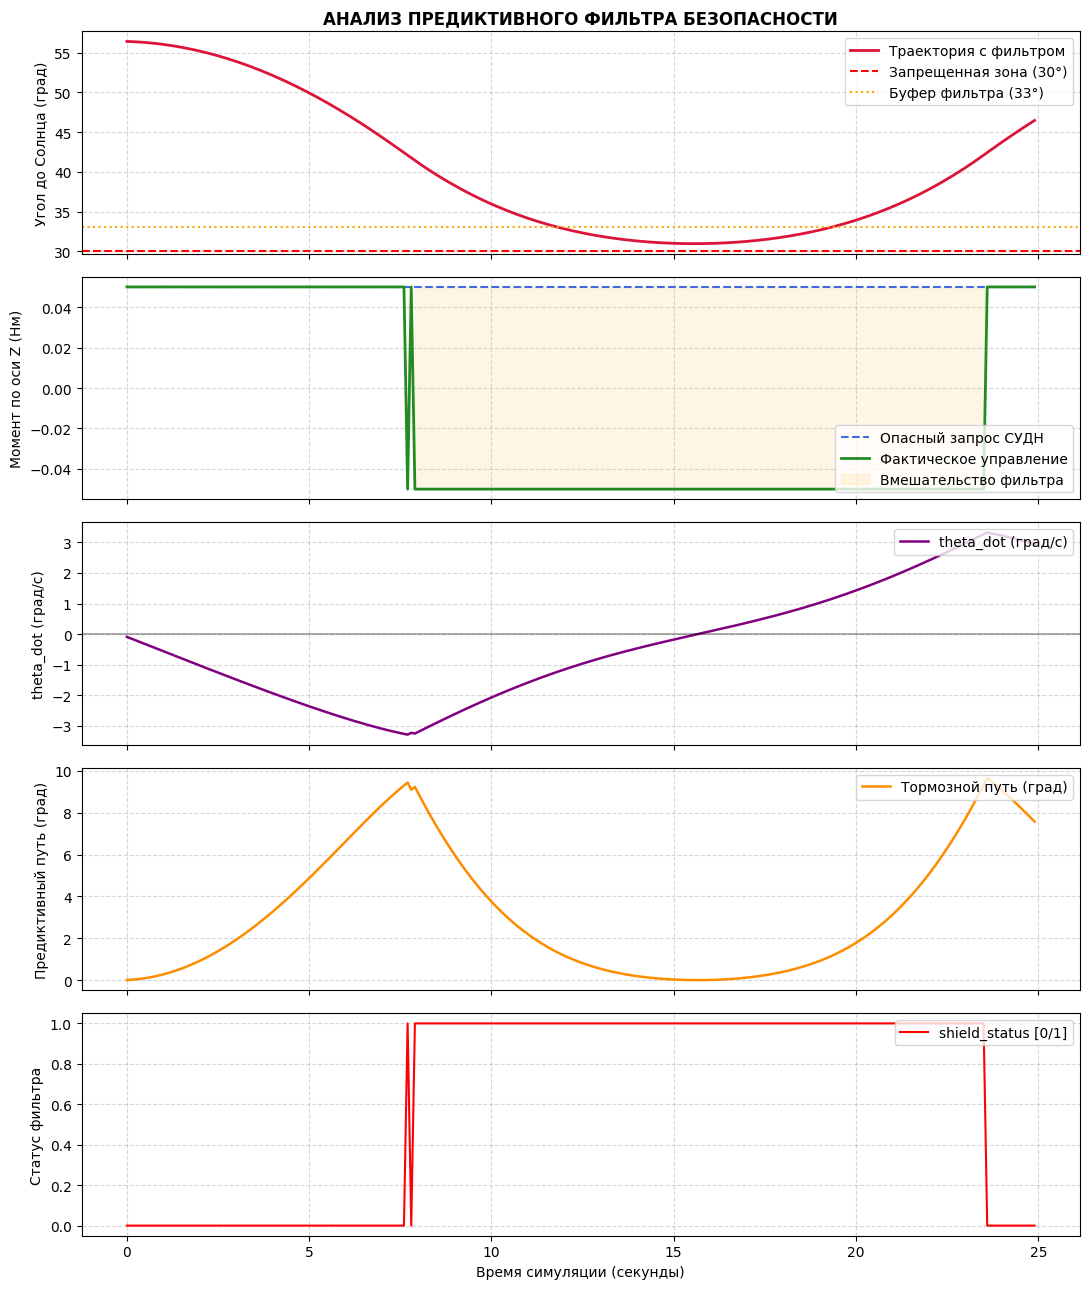

🟢 ТЕСТ 6 ПРОЙДЕН! Минимальный зафиксированный угол: 30.96°


In [120]:
import numpy as np
import matplotlib.pyplot as plt

# =====================================================================
# ТЕСТ 6: ПРОВЕРКА ПРЕДИКТИВНОГО ФИЛЬТРА
# =====================================================================
print("⏳ Запуск верификационного Теста №6...")

test6_config = SPACECRAFT_CONFIG.copy()
test6_config["max_episode_steps"] = 250
env_test6 = Case3SafePhysicsEnv(config=test6_config, reward_config=REWARD_CONFIG)

# Штатный сброс среды (очищает триггеры гистерезиса)
env_test6.reset(seed=42)

# деструктивный запрос ИНС строго в сторону Солнца
fixed_dangerous_action = np.array([0.0, 0.0, 1.0], dtype=np.float32)

# Буферы отрисовки графиков
time_hist = []
sun_angle_hist = []
applied_moment_z_hist = []
dangerous_request_z_hist = []
filter_zone_hist = []
theta_dot_hist = []
braking_angle_hist = []
sun_fault_predicted_hist = []

for step in range(test6_config["max_episode_steps"]):
    # 1. Запрашиваем штатные относительные элементы ДО выполнения физического шага
    q_current, omega_rel = env_test6._get_relative_elements()
    
    # 2. Выполняем честный шаг симуляции
    next_obs, reward, _, _, info = env_test6.step(fixed_dangerous_action)
    
    # 3. РАСЧЕТ ДИАГНОСТИКИ ВНУТРИ ТЕСТА
    sun_B = rotate_vector_by_quat(test6_config["sun_vector_N"], quat_conjugate(q_current))
    sun_B_norm = sun_B / np.linalg.norm(sun_B)
    r_B = test6_config["sensor_axis_B"]
    cos_angle = np.clip(np.dot(r_B, sun_B_norm), -1.0, 1.0)
    current_angle_deg = np.degrees(np.arccos(cos_angle))
    
    # Аналитическая скорость сближения Пуассона (в чистых физических рад/с -> град/с)
    sin_angle = np.sqrt(1.0 - cos_angle**2)
    if sin_angle > 1e-4:
        theta_dot_deg_s = np.degrees(-np.dot(omega_rel, np.cross(r_B, sun_B_norm)) / sin_angle)
    else:
        theta_dot_deg_s = 0.0
        
    # Тормозной путь по Ньютону на основе параметров из конфига объекта
    max_u = env_test6.config["max_u_torque"]
    max_J_axis = float(np.max(np.linalg.eigvals(env_test6.config["J_B"])))
    epsilon_max = max_u / max_J_axis
    omega_approach = np.abs(np.radians(theta_dot_deg_s))
    braking_angle_val = np.degrees((omega_approach ** 2) / (2.0 * epsilon_max))
    
    # Извлечение параметров шага из официального info среды
    applied_action = info.get("applied_action", fixed_dangerous_action)
    is_filter_active = info.get("filter_activated", False)
    
    # Заполнение истории
    time_hist.append(step * test6_config["dt"])
    sun_angle_hist.append(current_angle_deg)
    applied_moment_z_hist.append(applied_action[2] * test6_config["max_u_torque"])
    dangerous_request_z_hist.append(fixed_dangerous_action[2] * test6_config["max_u_torque"])
    filter_zone_hist.append(1.0 if is_filter_active else 0.0)
    
    # Наполнение диагностических буферов честными вычисленными данными
    theta_dot_hist.append(theta_dot_deg_s)
    braking_angle_hist.append(braking_angle_val)
    sun_fault_predicted_hist.append(1.0 if is_filter_active else 0.0)

# =====================================================================
# ОТРИСОВКА ГРАФИКОВ
# =====================================================================
fig, (ax1, ax2, ax3, ax4, ax5) = plt.subplots(5, 1, figsize=(11, 13), sharex=True)

ax1.plot(time_hist, sun_angle_hist, color="crimson", linewidth=2, label="Траектория с фильтром")
ax1.axhline(y=test6_config["exclusion_cone_angle_deg"], color="red", linestyle="--", label="Запрещенная зона (30°)")
ax1.axhline(y=test6_config["exclusion_cone_angle_deg"]+test6_config["shield_safety_buffer_deg"], color="orange", linestyle=":", label="Буфер фильтра (33°)")
ax1.set_ylabel("Угол до Солнца (град)")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="upper right")
ax1.set_title("АНАЛИЗ ПРЕДИКТИВНОГО ФИЛЬТРА БЕЗОПАСНОСТИ", fontsize=12, fontweight="bold")

ax2.plot(time_hist, dangerous_request_z_hist, color="royalblue", linestyle="--", label="Опасный запрос СУДН")
ax2.plot(time_hist, applied_moment_z_hist, color="forestgreen", linewidth=2, label="Фактическое управление")
ax2.fill_between(time_hist, -0.05, 0.05, where=np.array(filter_zone_hist) > 0, color="orange", alpha=0.1, label="Вмешательство фильтра")
ax2.set_ylabel("Момент по оси Z (Нм)")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="lower right")

ax3.plot(time_hist, theta_dot_hist, color="purple", linewidth=1.8, label="theta_dot (град/с)")
ax3.axhline(y=0.0, color="black", linestyle="-", alpha=0.3)
ax3.set_ylabel("theta_dot (град/с)")
ax3.grid(True, linestyle="--", alpha=0.5)
ax3.legend(loc="upper right")

ax4.plot(time_hist, braking_angle_hist, color="darkorange", linewidth=1.8, label="Тормозной путь (град)")
ax4.set_ylabel("Предиктивный путь (град)")
ax4.grid(True, linestyle="--", alpha=0.5)
ax4.legend(loc="upper right")

ax5.plot(time_hist, sun_fault_predicted_hist, color="red", linewidth=1.5, label="shield_status [0/1]")
ax5.set_ylabel("Статус фильтра")
ax5.set_xlabel("Время симуляции (секунды)")
ax5.grid(True, linestyle="--", alpha=0.5)
ax5.legend(loc="upper right")

plt.tight_layout()
plt.show()

print(f"🟢 ТЕСТ 6 ПРОЙДЕН! Минимальный зафиксированный угол: {min(sun_angle_hist):.2f}°")


### Проверочный запуск сред и аудит размерностей
Ячейка выполняет один тестовый шаг в каждой среде со случайным управляющим воздействием (`action_space.sample()`). 
Это необходимо для проверки корректности сборки векторов состояний, отработки цепочки наследования конструкторов и исключения ошибок несовпадения типов данных.

In [121]:
# =====================================================================
# Демонстрационный запуск сред
# =====================================================================
envs = {
    "1. Black-Box": Case1BlackBoxEnv(config=SPACECRAFT_CONFIG, reward_config=REWARD_CONFIG),
    "2. PI-RL (Lyapunov)": Case2PhysicsInformedEnv(config=SPACECRAFT_CONFIG, reward_config=REWARD_CONFIG),
    "3. Safe PI-RL (Predictive Filter)": Case3SafePhysicsEnv(config=SPACECRAFT_CONFIG, reward_config=REWARD_CONFIG)
}
    
for name, env in envs.items():
    obs, _ = env.reset()
    print(f"\n--- Тестирование среды: {name} ---")
    print(f"Размерность пространства состояний: {obs.shape}")
        
    # Делаем один шаг со случайным действием
    action = env.action_space.sample()
    next_obs, reward, term, trunc, _ = env.step(action)
    print(f"Награда за шаг: {reward:.4f}, Terminated: {term}, Truncated: {trunc}")


--- Тестирование среды: 1. Black-Box ---
Размерность пространства состояний: (8,)
Награда за шаг: -18.8766, Terminated: False, Truncated: False

--- Тестирование среды: 2. PI-RL (Lyapunov) ---
Размерность пространства состояний: (8,)
Награда за шаг: -150.0008, Terminated: False, Truncated: True

--- Тестирование среды: 3. Safe PI-RL (Predictive Filter) ---
Размерность пространства состояний: (8,)
Награда за шаг: 0.0001, Terminated: False, Truncated: False


## Сравнительный анализ сходимости алгоритма PPO и сохранение моделей

Запускается полный цикл обучения агентов в трех разработанных конфигурациях сред. 
Сбор метрик (`timesteps` и `rewards`) осуществляется через встроенный механизм `Monitor`, после чего применяется процедура сглаживания данных скользящим средним. 
Итоговый график позволяет наглядно оценить влияние физически-информированной награды (PI-RL) и предиктивного фильтра безопасности (Safe RL) на скорость обучения и стабильность системы.

### Интерактивный мониторинг процесса обучения

В данном блоке реализован кастомный класс `RealTimePlottingCallback` для визуализации кривой обучения в реальном времени. Инструмент предназначен для оперативного контроля сходимости алгоритма PPO без использования внешних утилит логирования.

**Основные функции:**
* **Чтение логов:** Колбэк автоматически опрашивает файл `monitor.csv`, который генерируется оберткой `Monitor` при завершении каждого полетного эпизода.
* **Сглаживание данных:** Для построения основного тренда применяется скользящее среднее (Rolling Average), что позволяет сгладить случайные колебания наград за отдельные эпизоды.
* **Обновление графика:** Перерисовка графиков выполняется с фиксированной частотой (каждые 2048 шагов среды). Использование функции `clear_output` предотвращает накопление графических объектов в памяти Jupyter Notebook.

График позволяет отслеживать динамику изменения средней награды за эпизод непосредственно в процессе симуляции.

In [122]:
import os
import pandas as pd
from IPython.display import clear_output
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.monitor import Monitor

class RealTimePlottingCallback(BaseCallback):
    """
    Callback для SB3, который читает Monitor-логи с диска 
    и динамически перерисовывает сглаженную кривую наград прямо в ячейке Jupyter.
    """
    def __init__(self, log_dir, plot_freq=2048, window=10, verbose=0):
        super(RealTimePlottingCallback, self).__init__(verbose)
        self.log_dir = log_dir
        self.plot_freq = plot_freq  # Частота обновления графика (в шагах среды)
        self.window = window        # Окно сглаживания скользящим средним
        self.monitor_file = os.path.join(log_dir, "monitor.csv")

    def _on_step(self) -> bool:
        if self.n_calls % self.plot_freq == 0:
           #  print(f"Шаг {self.num_timesteps}: проверка файла логов...") 
            if os.path.exists(self.monitor_file):
                try:
                    # Читаем файл в защищенном режиме без skiprows, 
                    # Pandas сам автоматически распознает заголовок Monitor-лога
                    df = pd.read_csv(self.monitor_file, comment='#')
                    
                    if len(df) > 0:
                        ep_rewards = df['r'].values
                        ep_lengths = df['l'].values
                        timesteps = np.cumsum(ep_lengths)

                        clear_output(wait=True)
                        
                        # АКТИВИРУЕМ ИНТЕРАКТИВНЫЙ РЕЖИМ MATPLOTLIB
                        plt.ion() 
                        
                        fig, ax = plt.subplots(figsize=(9, 5))
                        ax.plot(timesteps, ep_rewards, alpha=0.15, color='green', label='Награда за эпизод')
                        
                        if len(ep_rewards) >= self.window:
                            smoothed_rewards = pd.Series(ep_rewards).rolling(window=self.window, min_periods=1).mean()
                            ax.plot(timesteps, smoothed_rewards, color='green', linewidth=2.5, label='Сглаженный тренд')
                        
                        ax.set_title(f"Мониторинг обучения (Шаг: {self.num_timesteps})", fontsize=11, fontweight='bold')
                        ax.set_xlabel("Шаги в симуляции (Timesteps)")
                        ax.set_ylabel("Интегральная награда за эпизод")
                        ax.grid(True, linestyle="--", alpha=0.5)
                        ax.legend(loc="lower left")
                                                
                        plt.draw()
                        plt.pause(0.001) 
                        plt.show()
                        
                except Exception as e:
                    # Если файл заблокирован SB3 на дозапись - выводим техническую ошибку в консоль для отладки
                    print(f"⚠️ Ошибка чтения лога: {e}")
        return True

### Настройки словарей

In [123]:
# =====================================================================
# ГЛОБАЛЬНЫЙ РЕЕСТР КЕЙСОВ И ФИЛЬТРЫ УПРАВЛЕНИЯ
# =====================================================================
# 1. Полный справочник всех существующих конфигураций сред
GLOBAL_ENV_REGISTRY = {
    "case_1": {
        "name": "Case 1: Black-Box RL",
        "class": Case1BlackBoxEnv,
        "folder": "case_1_black-box_rl",
        "color": "crimson"
    },
    "case_2": {
        "name": "Case 2: Physics-Informed RL",
        "class": Case2PhysicsInformedEnv,
        "folder": "case_2_physics-informed_rl",
        "color": "royalblue"
    },
    "case_3": {
        "name": "Case 3: Shielded PI-RL",
        "class": Case3SafePhysicsEnv,
        "folder": "case_3_shielded_pi_rl",
        "color": "forestgreen"
    }
}

# 2. АКТИВНЫЕ ФИЛЬТРЫ: Укажите ключи из реестра, которые нужно обрабатывать
# Вы можете оставить только ["case_3"], или ["case_2", "case_3"], или все три.
CASES_TO_TRAIN = ["case_1", "case_2", "case_3"]  # Какие кейсы запускать на ОБУЧЕНИЕ
CASES_TO_PLOT  = ["case_1", "case_2", "case_3"]  # Какие кейсы ВЫВОДИТЬ на график

CASES_TO_TRAIN = ["case_3"]

### Обучение моделей

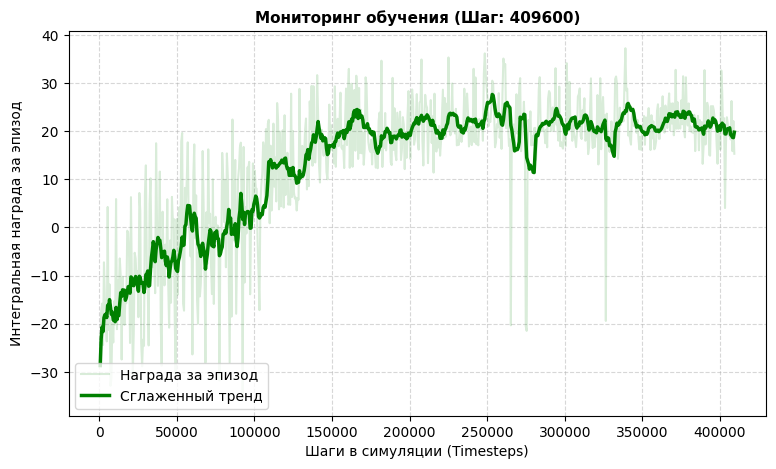

✅ Обучение для Case 3: Shielded PI-RL успешно завершено!
💾 Модель сохранена на диск: ./ppo_spacecraft_logs/case_3_shielded_pi_rl\case_3_shielded_pi_rl.zip

🎉 Все выбранные процессы обучения завершены!


In [124]:
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import EvalCallback

log_dir = "./ppo_spacecraft_logs/"
os.makedirs(log_dir, exist_ok=True)

print(f"Инициализация обучения. Фильтр активных задач: {CASES_TO_TRAIN}")

# Итерируемся по кейсам, выбранным в фильтре CASES_TO_TRAIN
for case_key in CASES_TO_TRAIN:
    if case_key not in GLOBAL_ENV_REGISTRY:
        print(f"⚠️ Ключ '{case_key}' не найден в глобальном реестре. Пропуск.")
        continue
        
    case_info = GLOBAL_ENV_REGISTRY[case_key]
    case_name = case_info["name"]
    EnvClass = case_info["class"]
    folder_name = case_info["folder"]
    
    print(f"\n🚀 Запуск обучения агента для: {case_name}...")
    
    # Создаем индивидуальный путь для логов
    case_sub_dir = os.path.join(log_dir, folder_name)
    os.makedirs(case_sub_dir, exist_ok=True)
    
    # Инициализация среды и логгера Monitor
    raw_env = EnvClass(config=SPACECRAFT_CONFIG, reward_config=REWARD_CONFIG)
    monitored_env = Monitor(raw_env, case_sub_dir)
    vec_env = DummyVecEnv([lambda: monitored_env])

    # 3. Инициализируем интерактивный колбэк
    # plot_freq=2048 означает, что график будет перерисовываться при каждом обновлении буфера PPO
    plot_callback = RealTimePlottingCallback(log_dir=case_sub_dir, plot_freq=PPO_HYPERPARAMS["n_steps"], window=10)
    
    
    # Создаем отдельную среду для детерминированной оценки и сохранения лучших весов
    eval_raw_env = EnvClass(config=SPACECRAFT_CONFIG, reward_config=REWARD_CONFIG)
    eval_env = Monitor(eval_raw_env)

    eval_callback = EvalCallback(
        eval_env,
        best_model_save_path=case_sub_dir,  # Сохранит best_model.zip в папку кейса
        log_path=case_sub_dir,
        eval_freq=10240,                    # Оценка каждые 5 обновлений буфера PPO
        n_eval_episodes=5,                  # Усреднение по 5 случайным начальным ориентациям
        deterministic=True,
        render=False,
        verbose=0
    )

    # Инициализация модели PPO с распаковкой глобальных гиперпараметров
    model = PPO(
        env=vec_env,
        seed=42,
        **{k: v for k, v in PPO_HYPERPARAMS.items() if k != "policy_kwargs"}, # Защита от дублирования ключей
        policy_kwargs=policy_kwargs
    )
    
    # Запуск обучения
    model.learn(
        total_timesteps=TOTAL_TRAINING_TIMESTEPS,
        callback=[plot_callback, eval_callback]
    )
    print(f"✅ Обучение для {case_name} успешно завершено!")
    
    # Формирование уникального имени файла и сохранение на жесткий диск
    model_save_path = os.path.join(case_sub_dir, f"{folder_name}.zip")
    model.save(model_save_path)
    print(f"💾 Модель сохранена на диск: {model_save_path}")

print("\n🎉 Все выбранные процессы обучения завершены!")


### Графики кривых обучения

Построение графиков из диска. Активный фильтр отрисовки: ['case_1', 'case_2', 'case_3']


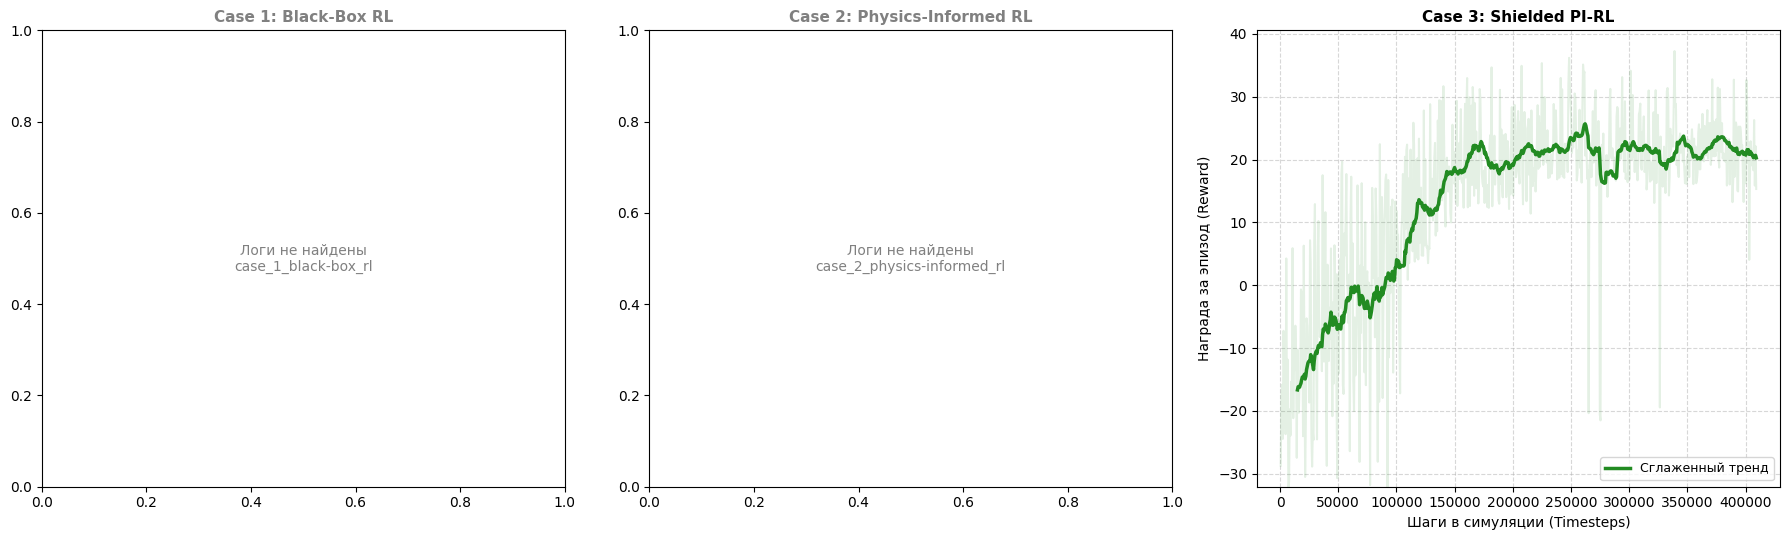

🎉 Графики успешно обновлены в файле 'rl_curves_filtered_panels.png'.


In [125]:
from stable_baselines3.common.results_plotter import load_results, ts2xy

log_dir = "./ppo_spacecraft_logs/"
window_size = 25  # Окно сглаживания тренда

# Фильтруем реестр: берем только те кейсы, которые указаны в CASES_TO_PLOT и реально существуют
active_plot_keys = [k for k in CASES_TO_PLOT if k in GLOBAL_ENV_REGISTRY]
num_plots = len(active_plot_keys)

if num_plots == 0:
    raise ValueError("❌ Список CASES_TO_PLOT пуст или содержит несуществующие ключи.")

# Динамически настраиваем размер сетки графиков в зависимости от количества выбранных кейсов
fig, axes = plt.subplots(1, num_plots, figsize=(6 * num_plots, 5.5), squeeze=False)
axes = axes.flatten()  # Гарантируем одномерный массив осей для итерации

print(f"Построение графиков из диска. Активный фильтр отрисовки: {active_plot_keys}")

for i, case_key in enumerate(active_plot_keys):
    case_info = GLOBAL_ENV_REGISTRY[case_key]
    case_name = case_info["name"]
    folder_name = case_info["folder"]
    color = case_info["color"]
    ax = axes[i]
    
    case_path = os.path.join(log_dir, folder_name)
    
    if not os.path.exists(case_path):
        ax.text(0.5, 0.5, f"Логи не найдены\n{folder_name}", ha='center', va='center', color='gray')
        ax.set_title(case_name, fontsize=11, fontweight="bold", color='gray')
        continue
        
    try:
        # Чтение Monitor.csv с жесткого диска
        x, y = ts2xy(load_results(case_path), 'timesteps')
        
        if len(y) >= window_size:
            # Расчет скользящего среднего
            y_smoothed = np.convolve(y, np.ones(window_size)/window_size, mode='valid')
            x_smoothed = x[len(x) - len(y_smoothed):]
            
            # Визуализация сырых данных и сглаженного тренда
            ax.plot(x, y, color=color, alpha=0.12)
            ax.plot(x_smoothed, y_smoothed, color=color, linewidth=2.5, label="Сглаженный тренд")
            
            # Адаптивное вычисление масштаба оси Y по перцентилям
            y_min_adaptive = np.percentile(y, 1.0)
            y_max_adaptive = np.max(y)
            y_range = y_max_adaptive - y_min_adaptive
            if y_range > 0:
                ax.set_ylim(y_min_adaptive - 0.05 * y_range, y_max_adaptive + 0.05 * y_range)
        elif len(y) > 0:
            ax.plot(x, y, color=color, linewidth=1.5, label="Сырые данные")
        else:
            ax.text(0.5, 0.5, "Файл лога пуст", ha='center', va='center', color='gray')
        
        # Стилизация субплота
        ax.set_title(case_name, fontsize=11, fontweight="bold")
        ax.set_xlabel("Шаги в симуляции (Timesteps)", fontsize=10)
        ax.set_ylabel("Награда за эпизод (Reward)", fontsize=10)
        ax.grid(True, linestyle="--", alpha=0.5)
        ax.legend(loc="lower right", fontsize=9)
        
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка чтения логов\n{str(e)}", ha='center', va='center', color='crimson')
        ax.set_title(case_name, fontsize=11, fontweight="bold", color='crimson')

plt.tight_layout()
# plt.savefig("rl_curves_filtered_panels.png", dpi=300, bbox_inches="tight")
plt.show()

print("🎉 Графики успешно обновлены в файле 'rl_curves_filtered_panels.png'.")


## 6: Проверка обученных моделей и анализ переходных процессов КА
Тестирование качества управления одной из обученных нейросетей PPO в детерминированном режиме (`deterministic=True`). 

Для смены анализируемого сценария достаточно изменить значение управляющей переменной `CHOSEN_CASE` в диапазоне от `1` до `3`. Скрипт самостоятельно:
1. Выберет соответствующий класс физической среды (`Case1`, `Case2` или `Case3`).
2. Автоматически сформирует корректный путь к zip-архиву с обученными весами модели.
3. Запустит демонстрационный маневр разворота и стабилизации КА из случайного начального положения.
4. Отрисует 4 синхронизированных во времени графика переходных процессов бортовой телеметрии: изменение компонентов кватерниона рассогласования, угловые скорости КА, управляющие моменты и накопление оборотов двигателей-маховиков.


📂 Запрос на чтение модели через реестр: ./ppo_spacecraft_logs/case_3_shielded_pi_rl\best_model.zip
✅ Успешная загрузка. Нейросеть ожидает входной вектор размерностью: 8
🚀 Запуск симуляции полета выбранного агента...
⏹️ Симуляция штатно завершена на 749-м шаге. Флаги: terminated=True, truncated=False
✅ Данные собраны. Переход к построению графиков...


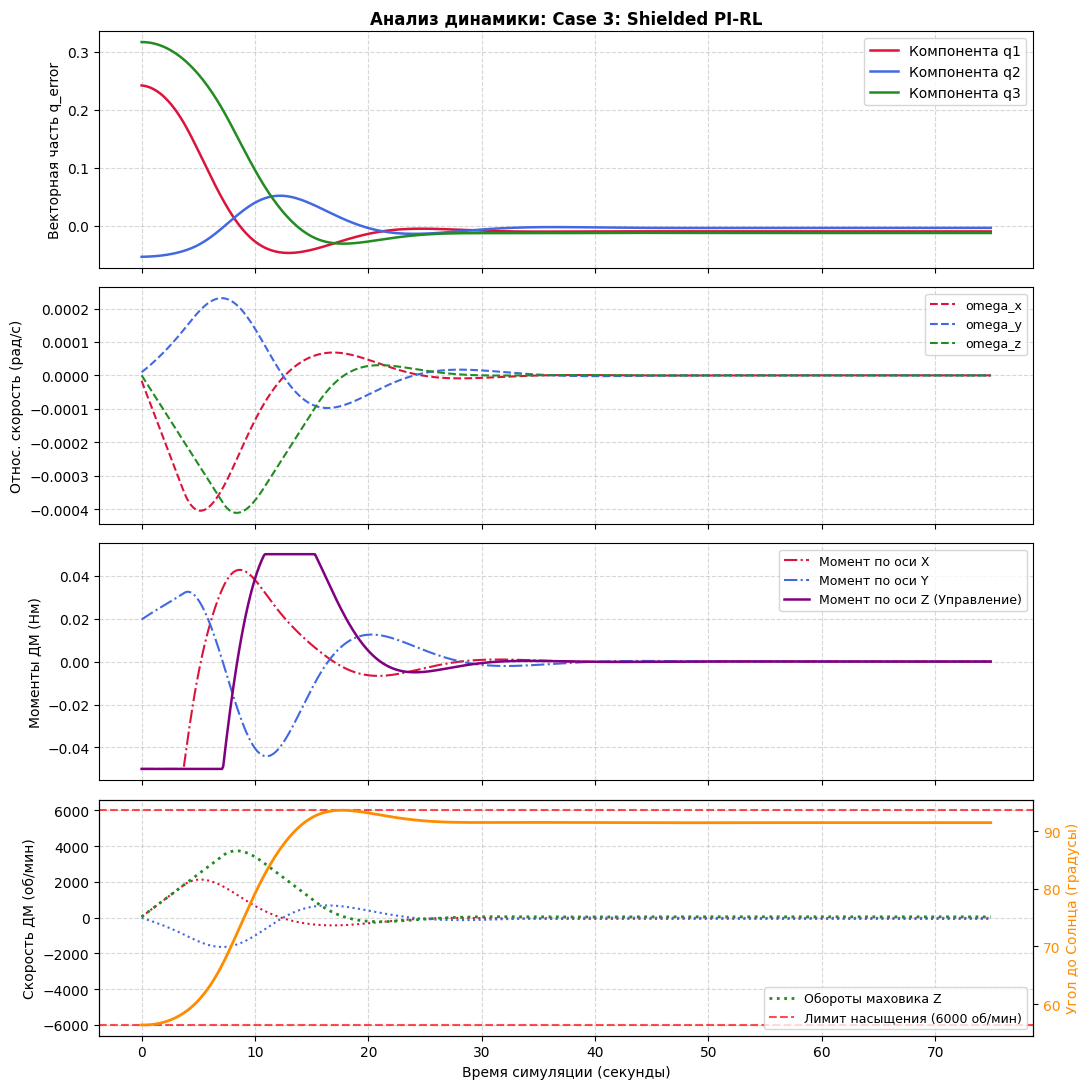


📋 Финальные метрики стабильности для Case 3: Shielded PI-RL:
 -> Модуль ошибки кватерниона: 0.01685
 -> Модуль относительной скорости: 0.00000 рад/с


In [126]:
# =====================================================================
# 1. ЗАГРУЗКА МОДЕЛИ С ДИСКА ЧЕРЕЗ ГЛОБАЛЬНЫЙ РЕЕСТР НАСТРОЕК
# =====================================================================
# Выберите ключ активного кейса из реестра: "case_1" | "case_2" | "case_3"
CHOSEN_CASE_KEY = "case_3"
LOAD_BEST = True  # True -> грузит best_model.zip, False -> грузит финальную {folder_name}.zip

# Автоматически извлекаем параметры из первой ячейки блокнота
case_info = GLOBAL_ENV_REGISTRY[CHOSEN_CASE_KEY]
SELECTED_ENV_CLASS = case_info["class"]
CHOSEN_CASE = case_info["name"]
folder_name = case_info["folder"]

log_dir = "./ppo_spacecraft_logs/"
filename = "best_model.zip" if LOAD_BEST else f"{folder_name}.zip"
model_disk_path = os.path.join(log_dir, folder_name, filename)

print(f"📂 Запрос на чтение модели через реестр: {model_disk_path}")
if not os.path.exists(model_disk_path):
    raise FileNotFoundError(f"❌ Файл весов не найден по пути {model_disk_path}. Проверьте фильтры обучения!")

# Загрузка весов конкретного агента
LOADED_MODEL = PPO.load(model_disk_path)
expected_shape = LOADED_MODEL.observation_space.shape[0]
print(f"✅ Успешная загрузка. Нейросеть ожидает входной вектор размерностью: {expected_shape}")

# =====================================================================
# 2. ЧЕСТНЫЙ ЗАПУСК СРЕДЫ ЧЕРЕЗ ШТАТНЫЙ RESET С ФИКСИРОВАННЫМ SEED
# =====================================================================
validation_config = SPACECRAFT_CONFIG.copy()
# Даем честные 75 секунд времени симуляции для раскрытия всей Bang-Bang динамики
validation_config["max_episode_steps"] = 750  

# Инициализируем верификационную среду с раздельной передачей физики и наград
test_env = SELECTED_ENV_CLASS(config=validation_config, reward_config=REWARD_CONFIG)

# Сброс среды с фиксацией seed для воспроизводимости переходных процессов
obs, _ = test_env.reset(seed=42) 

# Гарантируем, что маховики изначально неподвижны (угловой импульс равен нулю)
test_env.wheel_speeds = np.zeros(3, dtype=np.float32)
obs = test_env._get_obs()

# =====================================================================
# 3. СБОР ПОЛНОЙ ТЕЛЕМЕТРИИ СТРОГО ИЗ ЖИВОГО ВЕКТОРА НАБЛЮДЕНИЙ OBS
# =====================================================================
time_hist = []
q_components_hist = []
omega_rel_components_hist = []
applied_moments_hist = []
wheel_speeds_rpm_hist = []
angle_sun_hist = []
filter_active_hist = []

print("🚀 Запуск симуляции полета выбранного агента...")

for step in range(validation_config["max_episode_steps"]):
    current_obs = obs
        
    # Запрос детерминированного оптимального действия у нейросети PPO
    action, _ = LOADED_MODEL.predict(current_obs, deterministic=True)
    
    # Исполнение физического шага интеграции RK4 в среде
    next_obs, reward, terminated, truncated, info = test_env.step(action)
    
    # --- ДЕНОРМИРОВАНИЕ И РАСПАКОВКА ДАННЫХ ИЗ ЖИВОГО ВЕКТОРА OBS ---
    # Первые 4 элемента — относительный кватернион ошибки q_err [q0, q1, q2, q3] (без скейлинга)
    q_curr = next_obs[0:4].copy()
    
    # Элементы с 4 по 7 — угловая скорость корпуса КА со скейлингом. 
    # Умножаем её обратно на init_max_omega для вывода честных физических рад/с на графики!
    w_scaled = next_obs[4:7].copy()
    omega_rel = w_scaled * validation_config["init_max_omega"]
    
    # Геометрический расчет текущего угла оптической оси КА до вектора на Солнце
    sun_B = rotate_vector_by_quat(validation_config["sun_vector_N"], quat_conjugate(q_curr))
    sun_B_norm = sun_B / np.linalg.norm(sun_B)
    angle_deg = np.degrees(np.arccos(np.clip(np.dot(validation_config["sensor_axis_B"], sun_B_norm), -1.0, 1.0)))
    
    # Чтение параметров интервенции аналитического фильтра безопасности из словаря info
    applied_action = info.get("applied_action", action)
    is_filter_active = info.get("filter_activated", False)
    
    # Извлечение реальных скоростей роторов маховиков и перевод рад/с строго в об/мин
    wheel_speeds_rpm = test_env.wheel_speeds.copy() * (60.0 / (2.0 * np.pi))
    
    # Фиксация параметров шага в массивы истории телеметрии
    time_hist.append(step * validation_config["dt"])
    q_components_hist.append(q_curr[1:4])  # Накапливаем векторную часть кватерниона [q1, q2, q3]
    omega_rel_components_hist.append(omega_rel)
    applied_moments_hist.append(applied_action * validation_config["max_u_torque"])
    wheel_speeds_rpm_hist.append(wheel_speeds_rpm)
    angle_sun_hist.append(angle_deg)
    filter_active_hist.append(1.0 if is_filter_active else 0.0)
    
    # Обновляем марковское наблюдение и проверяем условия завершения
    obs = next_obs
    if terminated or truncated:
        print(f"⏹️ Симуляция штатно завершена на {step}-м шаге. Флаги: terminated={terminated}, truncated={truncated}")
        break

# Перевод списков истории в строго форматированные NumPy-массивы для Matplotlib
q_components_hist = np.array(q_components_hist)
omega_rel_components_hist = np.array(omega_rel_components_hist)
applied_moments_hist = np.array(applied_moments_hist)
wheel_speeds_rpm_hist = np.array(wheel_speeds_rpm_hist)

print("✅ Данные собраны. Переход к построению графиков...")

# =====================================================================
# 4. ПОСТРОЕНИЕ 4 СИНХРОНИЗИРОВАННЫХ ГРАФИКОВ (КОМПЛЕКСНЫЙ АУДИТ)
# =====================================================================
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(11, 11), sharex=True)

# Окно 1: Компоненты векторной части кватерниона рассогласования
ax1.plot(time_hist, q_components_hist[:, 0], label="Компонента q1", color="crimson", linewidth=1.8)
ax1.plot(time_hist, q_components_hist[:, 1], label="Компонента q2", color="royalblue", linewidth=1.8)
ax1.plot(time_hist, q_components_hist[:, 2], label="Компонента q3", color="forestgreen", linewidth=1.8)
ax1.set_ylabel("Векторная часть q_error")
ax1.set_title(f"Анализ динамики: {CHOSEN_CASE}", fontsize=12, fontweight="bold")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="upper right")

# Окно 2: Относительная угловая скорость корпуса КА в связанных осях
ax2.plot(time_hist, omega_rel_components_hist[:, 0], color="crimson", linestyle="--", linewidth=1.5, label="omega_x")
ax2.plot(time_hist, omega_rel_components_hist[:, 1], color="royalblue", linestyle="--", linewidth=1.5, label="omega_y")
ax2.plot(time_hist, omega_rel_components_hist[:, 2], color="forestgreen", linestyle="--", linewidth=1.5, label="omega_z")
ax2.set_ylabel("Относ. скорость (рад/с)")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="upper right", fontsize=9)

# Окно 3: Фактически приложенные моменты маховиков (Нм)
ax3.plot(time_hist, applied_moments_hist[:, 0], color="crimson", linestyle="-.", linewidth=1.5, label="Момент по оси X")
ax3.plot(time_hist, applied_moments_hist[:, 1], color="royalblue", linestyle="-.", linewidth=1.5, label="Момент по оси Y")
ax3.plot(time_hist, applied_moments_hist[:, 2], color="purple", linestyle="-", linewidth=1.8, label="Момент по оси Z (Управление)")
ax3.set_ylabel("Моменты ДМ (Нм)")
ax3.grid(True, linestyle="--", alpha=0.5)
ax3.legend(loc="upper right", fontsize=9)

# Окно 4: Динамика накопления оборотов двигателей-маховиков (об/мин)
ax4.plot(time_hist, wheel_speeds_rpm_hist[:, 0], color="crimson", linestyle=":")
ax4.plot(time_hist, wheel_speeds_rpm_hist[:, 1], color="royalblue", linestyle=":")
ax4.plot(time_hist, wheel_speeds_rpm_hist[:, 2], color="forestgreen", linestyle=":", linewidth=2, label="Обороты маховика Z")
ax4.axhline(y=validation_config["max_wheel_speed_rpm"], color="red", linestyle="--", alpha=0.7, label="Лимит насыщения (6000 об/мин)")
ax4.axhline(y=-validation_config["max_wheel_speed_rpm"], color="red", linestyle="--", alpha=0.7)
ax4.set_ylabel("Скорость ДМ (об/мин)")
ax4.set_xlabel("Время симуляции (секунды)")
ax4.grid(True, linestyle="--", alpha=0.5)
ax4.legend(loc="lower right", fontsize=9)

# Duplicated axis for Sun angle
ax4_twin = ax4.twinx()
ax4_twin.plot(time_hist, angle_sun_hist, color="darkorange", linewidth=2, label="Угол до Солнца")
ax4_twin.set_ylabel("Угол до Солнца (градусы)", color="darkorange")
ax4_twin.tick_params(axis='y', labelcolor="darkorange")

ax4.fill_between(time_hist, -6000, 6000, where=np.array(filter_active_hist) > 0, color="orange", alpha=0.06)

plt.tight_layout()
plt.show()

print(f"\n📋 Финальные метрики стабильности для {CHOSEN_CASE}:")
print(f" -> Модуль ошибки кватерниона: {np.linalg.norm(q_components_hist[-1]):.5f}")
print(f" -> Модуль относительной скорости: {np.linalg.norm(omega_rel_components_hist[-1]):.5f} рад/с")


### Тестовые сценарии для поверки выученной стратегии управления


In [ ]:
# Словарь валидационных сценариев [q0, q1, q2, q3, wx, wy, wz]
validation_cases = {
    "1. Идеальный надир": np.array([1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], dtype=np.float32),
    "2. Разворот на 180°": np.array([0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0], dtype=np.float32),
    "3. Попутное возмущение": np.array([0.707, 0.707, 0.0, 0.0, 0.001, 0.001, 0.0], dtype=np.float32),
    "4. Стресс-кувырок к Солнцу": np.array([0.5, 0.5, -0.5, 0.5, -0.001, 0.001, 0.001], dtype=np.float32)
}

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

print("📊 Запуск комплексной валидации обученного PPO-агента...")
validation_config = SPACECRAFT_CONFIG.copy()
validation_config["max_episode_steps"] = 1500 

for case_name, init_state in validation_cases.items():
    # Инициализация чистой среды
    val_env = Case3SafePhysicsEnv(config=validation_config, reward_config=REWARD_CONFIG)
    obs, _ = val_env.reset(seed=42)
    
    # Жестко подменяем начальное физическое состояние под сценарий
    val_env.state = init_state.copy()
    if case_name == "2. Разворот на 180°":
        # Микро-смещение от идеальной сингулярности 180 градусов, как в реальном полете
        val_env.state[1] = 0.999
        val_env.state[2] = 0.045
    val_env.state[0:4] /= np.linalg.norm(val_env.state[0:4]) # Нормировка кватерниона
    val_env.wheel_speeds = np.zeros(3, dtype=np.float32)     # Маховики изначально неподвижны
    
    # Буферы для сбора телеметрии сценария
    time_hist = []
    q_err_hist = []
    w_err_hist = []
    
    obs = val_env._get_obs()
    
    for step in range(SPACECRAFT_CONFIG["max_episode_steps"]):
        # Опрашиваем исключительно обученную ИНС (без исследовательского шума)
        action, _ = model.predict(obs, deterministic=True)
        
        next_obs, _, terminated, truncated, info = val_env.step(action)
        
        # Считываем штатные элементы рассогласования
        q_err, omega_rel = val_env._get_relative_elements()
        q_err_norm = np.linalg.norm(q_err[1:4])
        w_err_norm = np.linalg.norm(omega_rel)
        
        time_hist.append(step * SPACECRAFT_CONFIG["dt"])
        q_err_hist.append(q_err_norm)
        w_err_hist.append(w_err_norm)
        
        obs = next_obs
        if terminated or truncated:
            break
            
    # Добавляем линии сценария на графики
    ax1.plot(time_hist, q_err_hist, linewidth=2, label=case_name)
    ax2.plot(time_hist, w_err_hist, linewidth=2, label=case_name)

# Оформление графиков телеметрии
ax1.set_ylabel("Норма ошибки кватерниона ||q_err||")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="upper right")
ax1.set_title("РЕЗУЛЬТАТЫ СТРЕСС-ВАЛИДАЦИИ ИНС НА ЭТАЛОННЫХ СЦЕНАРИЯХ", fontsize=12, fontweight="bold")

ax2.set_ylabel("Угловая скорость ошибки ||w_err|| (рад/с)")
ax2.set_xlabel("Время полета (секунды)")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()
